# Airtel Telecom Analytics – Assignment 07: Statistical Validation
## Recharge Behaviour and Customer Retention Analysis

## 1. Introduction

**Business problem.** The Airtel customer-retention team wants to know whether recharge behaviour is *associated* with customer churn. Customers who churn may recharge less often, spend less, or have a different tenure from customers who stay.

**Objectives**
1. Build a clean **subscriber-level** dataset (one row per subscriber) from `airtel.db` using SQL and Python.
2. Use suitable statistical tests to compare churned and retained subscribers.
3. Judge both **statistical significance** (p-value at α = 0.05) and **practical importance** (size of the difference in real units).
4. Explain the limits of the analysis. This is observational data, so we do **not** claim causation.

**Research questions**

| # | Research question |
|---|---|
| RQ1 | Do churned and retained subscribers differ in **total recharge amount** over six months? |
| RQ2 | Do they differ in **number of recharge transactions**? |
| RQ3 | Do they differ in **average recharge amount per transaction** (recharge-active subscribers only)? |
| RQ4 | Is the **churn rate** different for low-frequency and high-frequency rechargers? |
| RQ5 | Do churned and retained subscribers differ in **tenure (days)**? |
| RQ6 | Does the RQ1 conclusion change if we remove subscribers with **zero** recharges? |

**Fixed settings:** analysis period 1 Jan 2025 – 30 Jun 2025 (SQL: `recharge_date >= '2025-01-01' AND recharge_date < '2025-07-01'`), significance level **α = 0.05**, all tests **two-tailed**.

## 2. Imports and database connection

We import the libraries, fix the analysis settings, find `airtel.db`, and define the helper `q(sql)` that runs a SQL query and returns a pandas DataFrame.

> If your earlier project already has a `q()` helper in a utility file, you can import that instead. This cell defines an equivalent one so the notebook runs from the first cell to the last without hidden variables.

In [1]:
import sqlite3, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.labelsize": 10})

# ---- fixed assignment settings -------------------------------------------------
ALPHA = 0.05
START, END = "2025-01-01", "2025-07-01"     # inclusive start, EXCLUSIVE end
OBS_DAYS = 181                              # 1 Jan - 30 Jun 2025

# ---- project folders (works when run from the repo root or from /notebooks) ----
ROOT    = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
FIGS    = REPORTS / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

def find_db(name="airtel.db"):
    """Look for the database in the usual project locations."""
    for p in [ROOT / name, ROOT / "data" / name, ROOT / "data" / "raw" / name,
              ROOT / "database" / name, Path("/mnt/user-data/uploads") / name]:
        if p.exists():
            return p
    hits = list(ROOT.rglob(name))
    if hits:
        return hits[0]
    raise FileNotFoundError(f"{name} not found - put it in the project folder or update find_db().")

DB_PATH = find_db()
conn = sqlite3.connect(DB_PATH)

def q(sql, params=None):
    """Run a SQL query on airtel.db and return a DataFrame."""
    return pd.read_sql_query(sql, conn, params=params)

print("Database :", DB_PATH)
print("Reports  :", REPORTS)
print("Tables   :", q("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")["name"].tolist())

Database : c:\Users\dbila\Desktop\airtel-telecom-analytics\data\raw\airtel.db
Reports  : c:\Users\dbila\Desktop\airtel-telecom-analytics\reports
Tables   : ['circles', 'complaints', 'customer_features', 'customers', 'plans', 'recharges', 'usage_daily']


### Reusable helper functions

These helpers keep every test **consistent** and make sure each test is reported in the same 9-step order required by the assignment. They also stop very small p-values from being shown as exactly `0`: Python cannot store numbers below about 1e-308, so extremely small p-values are shown as `< 1e-300`.

In [2]:
R = {}   # every test result is stored here (one entry per test) -> used for the summary table, Excel and PDF

def fmt_p(p):
    """Format a p-value. Never show a tiny p-value as exactly 0."""
    if p < 1e-300:
        return "< 1e-300"
    if p < 0.0001:
        return f"{p:.2e}"
    return f"{p:.4f}"

def p_eq(p):
    """Text such as 'p = 1.39e-22' or 'p < 1e-300' (never 'p = 0')."""
    return "p < 1e-300" if p < 1e-300 else f"p = {fmt_p(p)}"

def p_cell(p):
    """Value stored in Excel: a number if representable, otherwise the text '< 1e-300'."""
    return float(p) if p >= 1e-300 else "< 1e-300"

def effect_label(d):
    """Rule-of-thumb labels for Cohen's d / Cohen's h."""
    d = abs(d)
    return "negligible" if d < 0.2 else "small" if d < 0.5 else "medium" if d < 0.8 else "large"

def describe(s):
    s = pd.Series(s).dropna().astype(float)
    return {"n": int(s.count()), "mean": s.mean(), "median": s.median(), "std dev": s.std(ddof=1),
            "min": s.min(), "max": s.max()}

def verdict_text(p, eff, rel_text):
    if p < ALPHA and eff in ("negligible", "small"):
        return f"Statistically significant, but the practical size of the difference is {eff} ({rel_text})."
    if p < ALPHA:
        return f"Statistically significant and the practical size is {eff} ({rel_text}), so it is large enough to matter to the business."
    return "Not statistically significant. This does not prove the groups are identical - there is simply not enough evidence of a difference."

def welch_report(tid, title, rq, h0, h1, why, g1, g2, a, b, unit, hint, supplementary=False):
    """Run Welch's two-sided t-test and print the full 9-step statistical report."""
    a = pd.Series(a).dropna().astype(float); b = pd.Series(b).dropna().astype(float)
    n1, n2 = len(a), len(b)
    v1, v2 = a.var(ddof=1) / n1, b.var(ddof=1) / n2
    se = np.sqrt(v1 + v2)
    t_stat, p_val = stats.ttest_ind(a, b, equal_var=False)            # Welch, two-tailed
    dof = (v1 + v2) ** 2 / (v1 ** 2 / (n1 - 1) + v2 ** 2 / (n2 - 1))   # Welch-Satterthwaite df
    diff = a.mean() - b.mean()
    tcrit = stats.t.ppf(1 - ALPHA / 2, dof)
    ci = (diff - tcrit * se, diff + tcrit * se)
    sp = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2))
    d = diff / sp
    eff = effect_label(d)
    _, p_mw = stats.mannwhitneyu(a, b, alternative="two-sided")        # robustness only
    decision = "Reject H0" if p_val < ALPHA else "Fail to reject H0"
    rel = diff / b.mean() * 100
    rel_text = f"{rel:+.1f}% relative to {g2}, Cohen's d = {d:.2f}"
    interp = verdict_text(p_val, eff, rel_text) + " " + hint

    da, db = describe(a), describe(b)
    group_values = (f"{g1}: mean {da['mean']:,.2f}, median {da['median']:,.2f}, SD {da['std dev']:,.2f} | "
                    f"{g2}: mean {db['mean']:,.2f}, median {db['median']:,.2f}, SD {db['std dev']:,.2f}  ({unit})")
    R[tid] = dict(id=tid, rq=rq, g1=g1, g2=g2, n1=n1, n2=n2, group_values=group_values,
                  diff_text=f"{diff:+,.2f} {unit} ({g1} minus {g2}); 95% CI [{ci[0]:,.2f}, {ci[1]:,.2f}]",
                  test="Welch's independent-samples t-test (two-tailed)", stat_name="t", stat=t_stat, df=dof,
                  p=p_val, decision=decision, interp=interp, h0=h0, h1=h1, direction="Two-tailed",
                  m1=da["mean"], m2=db["mean"], med1=da["median"], med2=db["median"],
                  sd1=da["std dev"], sd2=db["std dev"], diff=diff, rel=rel, d=d, eff=eff, ci=ci,
                  effect_text=f"Cohen's d = {d:.3f} ({eff})", p_mw=p_mw, unit=unit, supplementary=supplementary)

    display(Markdown(f"""
#### {tid} - {title}
**Step 1 - Research question and groups.** {rq}  Groups: **{g1}** (n = {n1:,}) vs **{g2}** (n = {n2:,}).

**Step 2 - Hypotheses.** H0: {h0}  |  H1: {h1}

**Step 3 - Test direction.** Two-tailed, because we only ask whether the groups *differ*, in either direction (decided before looking at results).

**Step 4 - Test used.** Welch's independent-samples t-test. {why}

**Step 5 - Descriptive statistics.**
"""))
    display(pd.DataFrame({g1: describe(a), g2: describe(b)}).T.style.format(precision=2, thousands=",").format({"n": "{:,.0f}"}))
    display(Markdown(f"""
**Step 6 - Test statistic and p-value.** t = {t_stat:.3f}, df = {dof:,.1f}, {p_eq(p_val)}  (Mann-Whitney U robustness check: {p_eq(p_mw)})

**Step 7 - Decision at α = {ALPHA}.** **{decision}**

**Step 8 - Difference in original units.** {g1} minus {g2} = **{diff:+,.2f} {unit}** (95% CI {ci[0]:,.2f} to {ci[1]:,.2f}); {rel:+.1f}% relative to the {g2} mean.

**Step 9 - Practical importance.** {interp}
"""))
    return R[tid]

def save_fig(fig, name):
    path = FIGS / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return path

## 3. Data inspection

### 3.1 Schema of the two tables
We confirm that every column required by the assignment exists. (`customer_features` has many other columns that we do not need.)

In [3]:
NEEDED = {
    "customer_features": ["customer_id", "is_churned", "connection_type", "tenure_days", "complaint_count"],
    "recharges":         ["customer_id", "recharge_date", "amount_inr"],
}
for table, cols in NEEDED.items():
    info = q(f"PRAGMA table_info({table})")
    missing = set(cols) - set(info["name"])
    assert not missing, f"Missing columns in {table}: {missing}"
    n_rows = q(f"SELECT COUNT(*) AS n FROM {table}")["n"][0]
    print(f"\n{table}: {n_rows:,} rows, {len(info)} columns in total. Columns used in this assignment:")
    display(info[info["name"].isin(cols)][["name", "type"]].reset_index(drop=True))
print("\nFull column list of recharges (for reference):", q("PRAGMA table_info(recharges)")["name"].tolist())


customer_features: 22,000 rows, 41 columns in total. Columns used in this assignment:


,name,type
0,customer_id,INT
1,tenure_days,INT
2,connection_type,TEXT
3,is_churned,INT
4,complaint_count,



recharges: 408,089 rows, 7 columns in total. Columns used in this assignment:


,name,type
0,customer_id,INTEGER
1,recharge_date,TEXT
2,amount_inr,INTEGER



Full column list of recharges (for reference): ['recharge_id', 'customer_id', 'recharge_date', 'amount_inr', 'plan_id', 'channel', 'txn_type']


### 3.2 Subscriber table checks (`customer_features`)
We count total and unique subscribers, look for duplicate `customer_id` values, and check for missing values in the columns we need.

In [4]:
cf_check = q("""
SELECT COUNT(*)                         AS total_rows,
       COUNT(DISTINCT customer_id)      AS unique_customers,
       SUM(customer_id IS NULL)         AS missing_customer_id,
       SUM(is_churned IS NULL)          AS missing_is_churned,
       SUM(tenure_days IS NULL)         AS missing_tenure_days,
       SUM(connection_type IS NULL)     AS missing_connection_type,
       SUM(complaint_count IS NULL)     AS missing_complaint_count
FROM customer_features
""")
display(cf_check.T.rename(columns={0: "value"}))

dup_ids = q("SELECT customer_id, COUNT(*) AS n FROM customer_features GROUP BY customer_id HAVING COUNT(*) > 1")
print("Duplicate customer_id values:", len(dup_ids))
display(q("SELECT is_churned, COUNT(*) AS subscribers, ROUND(100.0*COUNT(*)/SUM(COUNT(*)) OVER (), 2) AS pct FROM customer_features GROUP BY is_churned"))
display(q("SELECT connection_type, COUNT(*) AS subscribers FROM customer_features GROUP BY connection_type"))

,value
total_rows,22000
unique_customers,22000
missing_customer_id,0
missing_is_churned,0
missing_tenure_days,0
missing_connection_type,0
missing_complaint_count,0


Duplicate customer_id values: 0


,is_churned,subscribers,pct
0,0,16774,76.25
1,1,5226,23.75


,connection_type,subscribers
0,Postpaid,4851
1,Prepaid,17149


### 3.3 Recharge table checks (`recharges`)
We check missing IDs / dates / amounts, zero or negative amounts, date format, whether dates fall inside the analysis period, orphan customer IDs and exact duplicate rows.

In [5]:
rc_check = q("""
SELECT COUNT(*)                                              AS total_rows,
       SUM(customer_id IS NULL)                              AS missing_customer_id,
       SUM(recharge_date IS NULL)                            AS missing_recharge_date,
       SUM(amount_inr IS NULL)                               AS missing_amount,
       SUM(amount_inr = 0)                                   AS zero_amount,
       SUM(amount_inr < 0)                                   AS negative_amount,
       SUM(recharge_date NOT GLOB '[0-9][0-9][0-9][0-9]-[0-9][0-9]-[0-9][0-9]') AS bad_date_format,
       MIN(recharge_date)                                    AS first_date,
       MAX(recharge_date)                                    AS last_date,
       SUM(recharge_date <  :s)                              AS rows_before_period,
       SUM(recharge_date >= :s AND recharge_date < :e)       AS rows_inside_period,
       SUM(recharge_date >= :e)                              AS rows_after_period
FROM recharges
""", {"s": START, "e": END})
display(rc_check.T.rename(columns={0: "value"}))

orphans = q("SELECT COUNT(*) AS n FROM recharges WHERE customer_id NOT IN (SELECT customer_id FROM customer_features)")["n"][0]
exact_dups = q("""SELECT COUNT(*) AS n FROM (SELECT 1 FROM recharges GROUP BY customer_id, recharge_date, amount_inr, channel, txn_type
                  HAVING COUNT(*) > 1)""")["n"][0]
print("Recharge rows whose customer_id is not in customer_features:", orphans)
print("Groups of exact duplicate recharge rows:", exact_dups)

print("\nTransaction types inside the analysis period (the recharges table mixes two types):")
txn_mix = q("""
SELECT txn_type, COUNT(*) AS transactions, MIN(amount_inr) AS min_amount,
       ROUND(AVG(amount_inr),1) AS avg_amount, MAX(amount_inr) AS max_amount
FROM recharges WHERE recharge_date >= :s AND recharge_date < :e GROUP BY txn_type
""", {"s": START, "e": END})
display(txn_mix)

,value
total_rows,408089
missing_customer_id,0
missing_recharge_date,0
missing_amount,0
zero_amount,0
negative_amount,0
bad_date_format,0
first_date,2022-01-01
last_date,2025-06-27
rows_before_period,324396


Recharge rows whose customer_id is not in customer_features: 0
Groups of exact duplicate recharge rows: 0

Transaction types inside the analysis period (the recharges table mixes two types):


,txn_type,transactions,min_amount,avg_amount,max_amount
0,Bill Payment,26156,399,"1,079.90",1873
1,Recharge,57537,99,299.40,1799


### 3.4 Data-quality summary
All checks in one table. A **NOTE** means something to be aware of when interpreting results, not necessarily an error.

**Decision on transaction types.** The assignment defines recharge activity as the rows of the `recharges` table in the period. We follow that definition and keep every row, including rows with `txn_type = 'Bill Payment'`. The effect of this choice is discussed in the limitations (Section 8.3).

In [6]:
c, r_ = cf_check.iloc[0], rc_check.iloc[0]
bill_share = txn_mix.loc[txn_mix.txn_type == "Bill Payment", "transactions"].sum() / txn_mix["transactions"].sum() * 100
checks = [
    ("Total subscribers in customer_features",              f"{c.total_rows:,}",           "INFO"),
    ("Unique subscribers",                                  f"{c.unique_customers:,}",     "PASS" if c.total_rows == c.unique_customers else "FAIL"),
    ("Duplicate customer_id values",                        f"{len(dup_ids)}",             "PASS" if len(dup_ids) == 0 else "FAIL"),
    ("Missing customer_id (customer_features)",             f"{c.missing_customer_id}",    "PASS" if c.missing_customer_id == 0 else "FAIL"),
    ("Missing is_churned / tenure_days / connection_type / complaint_count",
        f"{c.missing_is_churned} / {c.missing_tenure_days} / {c.missing_connection_type} / {c.missing_complaint_count}",
        "PASS" if (c.missing_is_churned + c.missing_tenure_days + c.missing_connection_type + c.missing_complaint_count) == 0 else "FAIL"),
    ("Total rows in recharges (all dates)",                 f"{r_.total_rows:,}",          "INFO"),
    ("Missing customer_id (recharges)",                     f"{r_.missing_customer_id}",   "PASS" if r_.missing_customer_id == 0 else "FAIL"),
    ("Missing recharge_date",                               f"{r_.missing_recharge_date}", "PASS" if r_.missing_recharge_date == 0 else "FAIL"),
    ("Missing amount_inr",                                  f"{r_.missing_amount}",        "PASS" if r_.missing_amount == 0 else "FAIL"),
    ("Zero or negative amounts",                            f"{r_.zero_amount} zero / {r_.negative_amount} negative", "PASS" if (r_.zero_amount + r_.negative_amount) == 0 else "FAIL"),
    ("Dates not in YYYY-MM-DD format",                      f"{r_.bad_date_format}",       "PASS" if r_.bad_date_format == 0 else "FAIL"),
    ("Date range of recharges table",                       f"{r_.first_date} to {r_.last_date}", "INFO"),
    ("Rows BEFORE the analysis period (excluded by filter)", f"{r_.rows_before_period:,}", "NOTE"),
    ("Rows INSIDE the analysis period (used)",              f"{r_.rows_inside_period:,}",  "INFO"),
    ("Rows on/after 1 Jul 2025",                            f"{r_.rows_after_period:,}",   "PASS" if r_.rows_after_period == 0 else "NOTE"),
    ("Orphan recharge rows (customer not in customer_features)", f"{orphans}",             "PASS" if orphans == 0 else "FAIL"),
    ("Exact duplicate recharge rows",                       f"{exact_dups}",               "PASS" if exact_dups == 0 else "NOTE"),
    ("Share of in-period rows that are 'Bill Payment'",     f"{bill_share:.1f}%",          "NOTE"),
]
dq_summary = pd.DataFrame(checks, columns=["Check", "Result", "Status"])
display(dq_summary)
assert (dq_summary["Status"] != "FAIL").all(), "A data-quality check failed - investigate before continuing."

,Check,Result,Status
0,Total subscribers in customer_features,"22,000",INFO
1,Unique subscribers,"22,000",PASS
2,Duplicate customer_id values,0,PASS
3,Missing customer_id (customer_features),0,PASS
4,Missing is_churned / tenure_days / connection_...,0 / 0 / 0 / 0,PASS
5,Total rows in recharges (all dates),"408,089",INFO
6,Missing customer_id (recharges),0,PASS
7,Missing recharge_date,0,PASS
8,Missing amount_inr,0,PASS
9,Zero or negative amounts,0 zero / 0 negative,PASS


## 4. Subscriber-level dataset

**Why this step matters.** One subscriber can have many recharge transactions. If we compared transactions directly, the same subscriber would be counted many times and the tests would be wrong. So we first **aggregate to one row per subscriber**.

**Steps**
1. Filter recharges to `recharge_date >= '2025-01-01' AND recharge_date < '2025-07-01'`.
2. `GROUP BY customer_id` to get `recharge_count`, `total_recharge`, `average_recharge`, `active_recharge_months`.
3. **LEFT JOIN** this summary to `customer_features`, so subscribers with **no** recharge remain in the data (an INNER JOIN would silently delete them).
4. Subscribers with no recharges get `recharge_count = 0` and `total_recharge = 0` (via `COALESCE`). Their `average_recharge` stays missing (`NULL`) because an average of zero transactions is undefined.

In [7]:
SUMMARY_SQL = """
SELECT customer_id,
       COUNT(*)                                     AS recharge_count,
       SUM(amount_inr)                              AS total_recharge,
       AVG(amount_inr)                              AS average_recharge,
       COUNT(DISTINCT strftime('%Y-%m', recharge_date)) AS active_recharge_months
FROM recharges
WHERE recharge_date >= :s AND recharge_date < :e      -- inclusive start, exclusive end
  AND customer_id IS NOT NULL AND amount_inr IS NOT NULL
GROUP BY customer_id
"""

JOIN_SQL = f"""
WITH recharge_summary AS ({SUMMARY_SQL})
SELECT cf.customer_id, cf.is_churned, cf.connection_type, cf.tenure_days, cf.complaint_count,
       COALESCE(rs.recharge_count, 0)          AS recharge_count,
       COALESCE(rs.total_recharge, 0)          AS total_recharge,
       rs.average_recharge                     AS average_recharge,
       COALESCE(rs.active_recharge_months, 0)  AS active_recharge_months
FROM customer_features cf
LEFT JOIN recharge_summary rs ON rs.customer_id = cf.customer_id
"""
print(JOIN_SQL)

summary_only = q(SUMMARY_SQL, {"s": START, "e": END})
validation_df = q(JOIN_SQL, {"s": START, "e": END})
validation_df["status"] = np.where(validation_df["is_churned"] == 1, "Churned", "Retained")
print("\nSubscribers with at least one recharge in the period:", len(summary_only))
display(validation_df.head())


WITH recharge_summary AS (
SELECT customer_id,
       COUNT(*)                                     AS recharge_count,
       SUM(amount_inr)                              AS total_recharge,
       AVG(amount_inr)                              AS average_recharge,
       COUNT(DISTINCT strftime('%Y-%m', recharge_date)) AS active_recharge_months
FROM recharges
WHERE recharge_date >= :s AND recharge_date < :e      -- inclusive start, exclusive end
  AND customer_id IS NOT NULL AND amount_inr IS NOT NULL
GROUP BY customer_id
)
SELECT cf.customer_id, cf.is_churned, cf.connection_type, cf.tenure_days, cf.complaint_count,
       COALESCE(rs.recharge_count, 0)          AS recharge_count,
       COALESCE(rs.total_recharge, 0)          AS total_recharge,
       rs.average_recharge                     AS average_recharge,
       COALESCE(rs.active_recharge_months, 0)  AS active_recharge_months
FROM customer_features cf
LEFT JOIN recharge_summary rs ON rs.customer_id = cf.customer_id


Subscribers 

,customer_id,is_churned,connection_type,tenure_days,complaint_count,recharge_count,total_recharge,average_recharge,active_recharge_months,status
0,9,0,Prepaid,1030,3,5,1745,349.00,5,Retained
1,31,0,Prepaid,506,0,2,1438,719.00,2,Retained
2,151,0,Prepaid,1074,4,6,2094,349.00,5,Retained
3,186,0,Prepaid,1273,0,2,1438,719.00,2,Retained
4,207,1,Prepaid,198,3,2,418,209.00,2,Churned


### 4.1 Validation of the grain (one row per subscriber)

In [8]:
n_rows, n_unique = len(validation_df), validation_df["customer_id"].nunique()
n_zero = int((validation_df["recharge_count"] == 0).sum())
print(f"Rows in validation_df          : {n_rows:,}")
print(f"Unique customer_id values      : {n_unique:,}")
print(f"Subscribers in customer_features: {int(c.total_rows):,}")
print(f"Subscribers with NO recharge   : {n_zero:,} ({n_zero / n_rows:.1%}) - retained in the dataset by the LEFT JOIN")
assert n_rows == n_unique == int(c.total_rows), "Grain check failed: not one row per subscriber"
assert set(validation_df["is_churned"].unique()) <= {0, 1}
print("\nGrain check passed: exactly one row per subscriber.")

# Independent cross-check against the pre-computed columns already stored in customer_features
cross = validation_df.merge(q("SELECT customer_id, recharge_count AS cf_count, recharge_total_6m AS cf_total FROM customer_features"), on="customer_id")
mismatch = ((cross.recharge_count != cross.cf_count.fillna(0)) | (cross.total_recharge != cross.cf_total.fillna(0))).sum()
print(f"Cross-check vs customer_features.recharge_count / recharge_total_6m: {mismatch} mismatching subscribers")

display(validation_df.groupby("status")[["recharge_count", "total_recharge", "average_recharge", "active_recharge_months"]].agg(["count", "mean"]).T)

Rows in validation_df          : 22,000
Unique customer_id values      : 22,000
Subscribers in customer_features: 22,000
Subscribers with NO recharge   : 3,711 (16.9%) - retained in the dataset by the LEFT JOIN

Grain check passed: exactly one row per subscriber.
Cross-check vs customer_features.recharge_count / recharge_total_6m: 0 mismatching subscribers


status                        Churned  Retained
recharge_count         count 5,226.00 16,774.00
                       mean      2.02      4.36
total_recharge         count 5,226.00 16,774.00
                       mean    928.08  2,421.55
average_recharge       count 3,582.00 14,707.00
                       mean    515.47    593.62
active_recharge_months count 5,226.00 16,774.00
                       mean      1.75      3.90

## 5. Task 1 – Recharge behaviour of churned and retained subscribers

We compare **Churned** (`is_churned = 1`) and **Retained** (`is_churned = 0`) subscribers on three outcomes. Each test is **two-tailed** (we ask whether the groups differ in *either* direction).

### 5.1 Inspect distributions and extreme values first
Before reading any mean we look at the shape of the data: skewness, zeros, maximum values and outliers (values above Q3 + 1.5 × IQR).

n     mean   median  std dev   min  99th pct       max  skewness  % zeros  outliers (>Q3+1.5IQR)
metric                 group                                                                                                         
Total recharge (INR)   Churned    5226   928.08   563.00 1,391.84  0.00  7,072.25 10,689.00      3.08    31.46                    402
                       Retained  16774 2,421.55 1,495.00 2,644.70  0.00 10,407.00 10,939.00      1.79    12.32                   2920
Recharge count         Churned    5226     2.02     1.00     2.13  0.00     10.00     12.00      1.31    31.46                    116
                       Retained  16774     4.36     5.00     2.79  0.00     12.00     13.00      0.25    12.32                     60
Average recharge (INR) Churned    3582   515.47   399.00   426.12 99.00  1,799.00  1,871.00      1.71     0.00                    383
                       Retained  14707   593.62   479.00   430.90 99.00  1,769.48  1,823.17      1.40     0.00                   1306

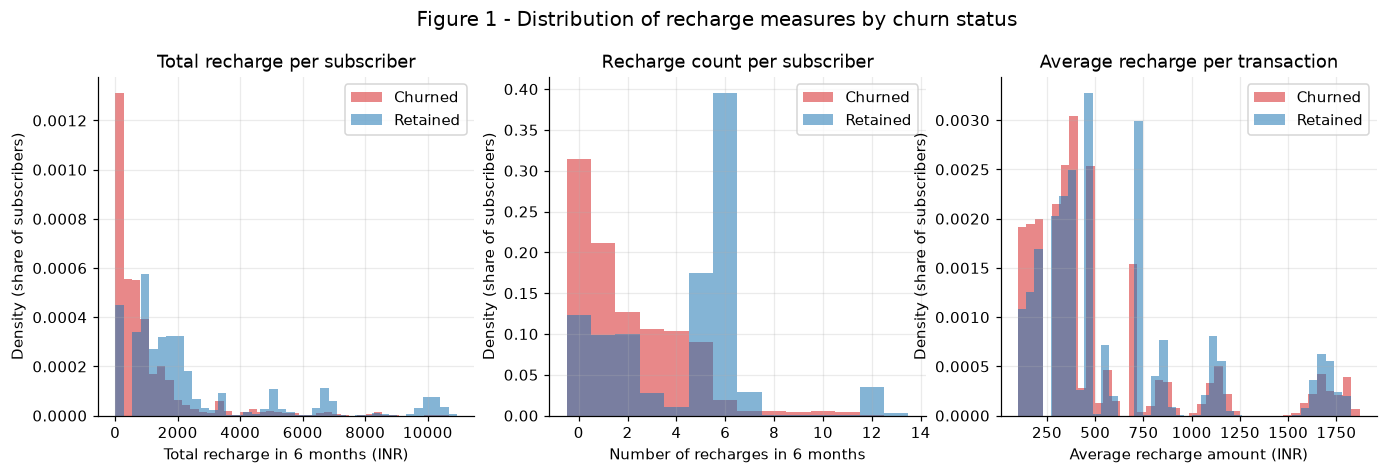

In [9]:
churned  = validation_df[validation_df["is_churned"] == 1]
retained = validation_df[validation_df["is_churned"] == 0]

def inspect(col, label):
    rows = []
    for name, g in [("Churned", churned), ("Retained", retained)]:
        s = g[col].dropna()
        q1, q3 = s.quantile([.25, .75])
        rows.append({"metric": label, "group": name, "n": len(s), "mean": s.mean(), "median": s.median(),
                     "std dev": s.std(), "min": s.min(), "99th pct": s.quantile(.99), "max": s.max(),
                     "skewness": s.skew(), "% zeros": (s == 0).mean() * 100,
                     "outliers (>Q3+1.5IQR)": int((s > q3 + 1.5 * (q3 - q1)).sum())})
    return pd.DataFrame(rows)

dist_table = pd.concat([inspect("total_recharge", "Total recharge (INR)"),
                        inspect("recharge_count", "Recharge count"),
                        inspect("average_recharge", "Average recharge (INR)")]).set_index(["metric", "group"])
display(dist_table)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
specs = [("total_recharge", "Total recharge per subscriber", "Total recharge in 6 months (INR)", 40),
         ("recharge_count", "Recharge count per subscriber", "Number of recharges in 6 months", np.arange(-0.5, 14.5, 1)),
         ("average_recharge", "Average recharge per transaction", "Average recharge amount (INR)", 40)]
for ax, (col, title, xl, bins) in zip(axes, specs):
    for lab, g, colr in [("Churned", churned, "#d62728"), ("Retained", retained, "#1f77b4")]:
        ax.hist(g[col].dropna(), bins=bins, density=True, alpha=0.55, label=lab, color=colr)
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel("Density (share of subscribers)"); ax.legend()
fig.suptitle("Figure 1 - Distribution of recharge measures by churn status", y=1.03, fontsize=13)
save_fig(fig, "fig1_distributions.png");

**What the distributions tell us (read the table and Figure 1 above)**
- All three measures are **right-skewed**: most subscribers have modest values, a few have very large ones. The skew is stronger for churned subscribers.
- **Total recharge** has a large spike at **0** (subscribers with no recharge), mostly in the churned group.
- Maximum values are far above the typical (median) value, so a few big spenders can pull the **mean** upwards. For this reason we always report the **median** next to the mean.

**Why Welch's t-test is still reasonable.** The groups are independent (different subscribers); the two groups have clearly different sizes and different standard deviations, so we use **Welch's** version, which does not assume equal variances. Sample sizes are in the thousands, so by the Central Limit Theorem the *sampling distribution of the mean* is close to normal even though the raw data are skewed. Because the data are skewed, we also run a rank-based **Mann-Whitney U** test as a robustness check (it is *not* used to replace the Welch decision).

### 5.2 Test 1A – Total recharge amount (six months)
- **Research question:** Does the mean total recharge amount differ between churned and retained subscribers?
- **H0:** μ(churned) = μ(retained) | **H1:** μ(churned) ≠ μ(retained) | **Two-tailed**, α = 0.05

In [10]:
t1a = welch_report(
    "A7-T1a", "Total recharge amount (six months), all subscribers",
    "Does mean total recharge amount over six months differ between churned and retained subscribers?",
    "Mean total recharge of churned subscribers = mean total recharge of retained subscribers.",
    "Mean total recharge of churned subscribers is different from that of retained subscribers.",
    "It compares the means of two independent groups with unequal sizes and unequal variances; n is large, so the mean is approximately normally distributed.",
    "Churned", "Retained", churned["total_recharge"], retained["total_recharge"], "INR",
    "Subscribers who left spent a lot less on recharges over the six months, which matters for revenue as well as retention.")


#### A7-T1a - Total recharge amount (six months), all subscribers
**Step 1 - Research question and groups.** Does mean total recharge amount over six months differ between churned and retained subscribers?  Groups: **Churned** (n = 5,226) vs **Retained** (n = 16,774).

**Step 2 - Hypotheses.** H0: Mean total recharge of churned subscribers = mean total recharge of retained subscribers.  |  H1: Mean total recharge of churned subscribers is different from that of retained subscribers.

**Step 3 - Test direction.** Two-tailed, because we only ask whether the groups *differ*, in either direction (decided before looking at results).

**Step 4 - Test used.** Welch's independent-samples t-test. It compares the means of two independent groups with unequal sizes and unequal variances; n is large, so the mean is approximately normally distributed.

**Step 5 - Descriptive statistics.**


,n,mean,median,std dev,min,max
Churned,"5,226",928.075775,563.000000,1391.839720,0.000000,10689.000000
Retained,"16,774",2421.553833,1495.000000,2644.700357,0.000000,10939.000000



**Step 6 - Test statistic and p-value.** t = -53.214, df = 16,921.5, p < 1e-300  (Mann-Whitney U robustness check: p < 1e-300)

**Step 7 - Decision at α = 0.05.** **Reject H0**

**Step 8 - Difference in original units.** Churned minus Retained = **-1,493.48 INR** (95% CI -1,548.49 to -1,438.47); -61.7% relative to the Retained mean.

**Step 9 - Practical importance.** Statistically significant and the practical size is medium (-61.7% relative to Retained, Cohen's d = -0.62), so it is large enough to matter to the business. Subscribers who left spent a lot less on recharges over the six months, which matters for revenue as well as retention.


### 5.3 Test 1B – Number of recharge transactions
- **Research question:** Does the mean number of recharge transactions differ between churned and retained subscribers?
- **H0:** μ(churned) = μ(retained) | **H1:** μ(churned) ≠ μ(retained) | **Two-tailed**, α = 0.05

In [11]:
t1b = welch_report(
    "A7-T1b", "Number of recharge transactions (six months), all subscribers",
    "Does the mean number of recharge transactions over six months differ between churned and retained subscribers?",
    "Mean number of recharges of churned subscribers = mean number of recharges of retained subscribers.",
    "Mean number of recharges of churned subscribers is different from that of retained subscribers.",
    "The count is a numeric outcome compared across two independent groups with unequal variances and large n, so the mean difference is tested with Welch's t-test.",
    "Churned", "Retained", churned["recharge_count"], retained["recharge_count"], "transactions",
    "Churned subscribers recharged noticeably less often; frequency of recharging is a useful engagement signal.")


#### A7-T1b - Number of recharge transactions (six months), all subscribers
**Step 1 - Research question and groups.** Does the mean number of recharge transactions over six months differ between churned and retained subscribers?  Groups: **Churned** (n = 5,226) vs **Retained** (n = 16,774).

**Step 2 - Hypotheses.** H0: Mean number of recharges of churned subscribers = mean number of recharges of retained subscribers.  |  H1: Mean number of recharges of churned subscribers is different from that of retained subscribers.

**Step 3 - Test direction.** Two-tailed, because we only ask whether the groups *differ*, in either direction (decided before looking at results).

**Step 4 - Test used.** Welch's independent-samples t-test. The count is a numeric outcome compared across two independent groups with unequal variances and large n, so the mean difference is tested with Welch's t-test.

**Step 5 - Descriptive statistics.**


,n,mean,median,std dev,min,max
Churned,"5,226",2.015499,1.000000,2.133701,0.000000,12.000000
Retained,"16,774",4.361512,5.000000,2.792831,0.000000,13.000000



**Step 6 - Test statistic and p-value.** t = -64.180, df = 11,289.6, p < 1e-300  (Mann-Whitney U robustness check: p < 1e-300)

**Step 7 - Decision at α = 0.05.** **Reject H0**

**Step 8 - Difference in original units.** Churned minus Retained = **-2.35 transactions** (95% CI -2.42 to -2.27); -53.8% relative to the Retained mean.

**Step 9 - Practical importance.** Statistically significant and the practical size is large (-53.8% relative to Retained, Cohen's d = -0.88), so it is large enough to matter to the business. Churned subscribers recharged noticeably less often; frequency of recharging is a useful engagement signal.


### 5.4 Test 1C – Average recharge amount per transaction (subscribers with at least one recharge)
Subscribers with no recharge have no average, so they are excluded **for this test only** (the sample sizes below are therefore smaller).
- **Research question:** Among subscribers who recharged at least once, does the mean average recharge amount per transaction differ between churned and retained subscribers?
- **H0:** μ(churned) = μ(retained) | **H1:** μ(churned) ≠ μ(retained) | **Two-tailed**, α = 0.05

In [12]:
t1c = welch_report(
    "A7-T1c", "Average recharge amount per transaction (recharge-active subscribers only)",
    "Among subscribers with at least one recharge, does the mean average recharge amount per transaction differ between churned and retained subscribers?",
    "Mean average recharge per transaction of churned subscribers = that of retained subscribers.",
    "Mean average recharge per transaction of churned subscribers is different from that of retained subscribers.",
    "Each subscriber contributes one average value; the two groups are independent, have similar-but-not-equal spread and large n, so Welch's t-test is appropriate.",
    "Churned", "Retained", churned["average_recharge"], retained["average_recharge"], "INR per transaction",
    "The gap per transaction is much smaller than the gap in total spend, so the main difference between the groups is how often they recharge, not how much they pay each time.")


#### A7-T1c - Average recharge amount per transaction (recharge-active subscribers only)
**Step 1 - Research question and groups.** Among subscribers with at least one recharge, does the mean average recharge amount per transaction differ between churned and retained subscribers?  Groups: **Churned** (n = 3,582) vs **Retained** (n = 14,707).

**Step 2 - Hypotheses.** H0: Mean average recharge per transaction of churned subscribers = that of retained subscribers.  |  H1: Mean average recharge per transaction of churned subscribers is different from that of retained subscribers.

**Step 3 - Test direction.** Two-tailed, because we only ask whether the groups *differ*, in either direction (decided before looking at results).

**Step 4 - Test used.** Welch's independent-samples t-test. Each subscriber contributes one average value; the two groups are independent, have similar-but-not-equal spread and large n, so Welch's t-test is appropriate.

**Step 5 - Descriptive statistics.**


,n,mean,median,std dev,min,max
Churned,"3,582",515.468747,399.000000,426.119163,99.000000,1871.000000
Retained,"14,707",593.621104,479.000000,430.900925,99.000000,1823.166667



**Step 6 - Test statistic and p-value.** t = -9.822, df = 5,503.7, p = 1.39e-22  (Mann-Whitney U robustness check: p = 4.78e-45)

**Step 7 - Decision at α = 0.05.** **Reject H0**

**Step 8 - Difference in original units.** Churned minus Retained = **-78.15 INR per transaction** (95% CI -93.75 to -62.55); -13.2% relative to the Retained mean.

**Step 9 - Practical importance.** Statistically significant, but the practical size of the difference is negligible (-13.2% relative to Retained, Cohen's d = -0.18). The gap per transaction is much smaller than the gap in total spend, so the main difference between the groups is how often they recharge, not how much they pay each time.


### 5.5 Figure 2 – Recharge behaviour comparison
Mean and median side by side. A large gap between mean and median is another sign of skewness.

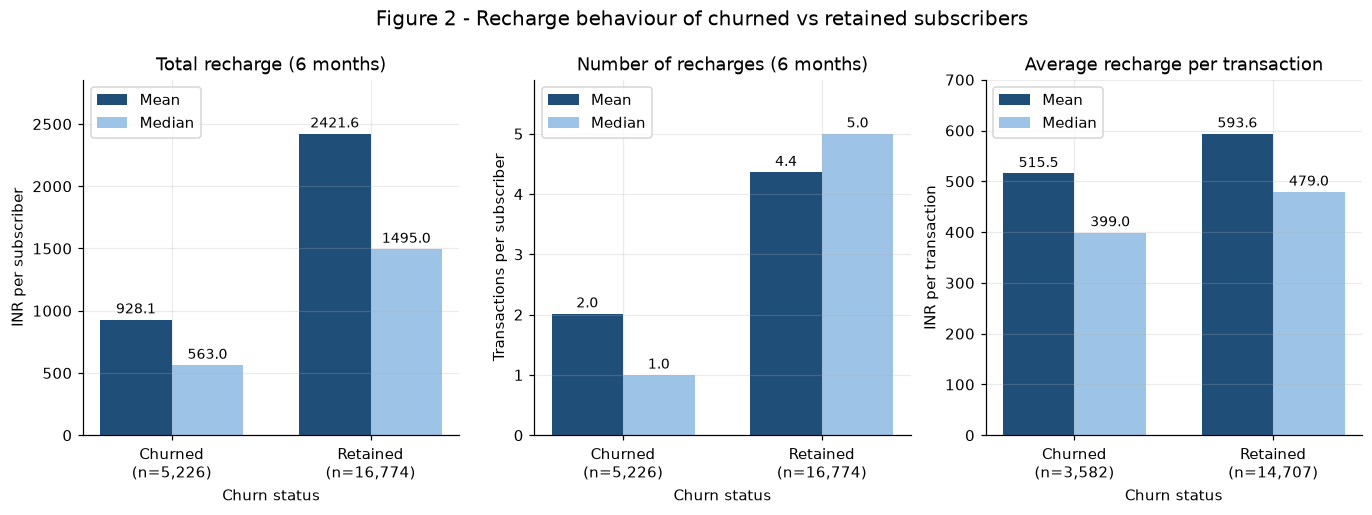

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, tid, ttl, yl in zip(axes, ["A7-T1a", "A7-T1b", "A7-T1c"],
        ["Total recharge (6 months)", "Number of recharges (6 months)", "Average recharge per transaction"],
        ["INR per subscriber", "Transactions per subscriber", "INR per transaction"]):
    r = R[tid]; x = np.arange(2); w = 0.36
    m = ax.bar(x - w / 2, [r["m1"], r["m2"]], w, label="Mean", color="#1f4e79")
    md_ = ax.bar(x + w / 2, [r["med1"], r["med2"]], w, label="Median", color="#9dc3e6")
    for bars in (m, md_):
        ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels([f"Churned\n(n={r['n1']:,})", f"Retained\n(n={r['n2']:,})"])
    ax.set_title(ttl); ax.set_xlabel("Churn status"); ax.set_ylabel(yl); ax.legend()
    ax.set_ylim(0, max(r["m1"], r["m2"], r["med1"], r["med2"]) * 1.18)
fig.suptitle("Figure 2 - Recharge behaviour of churned vs retained subscribers", y=1.03, fontsize=13)
save_fig(fig, "fig2_recharge_comparison.png");

## 6. Task 2 – Recharge frequency and churn rate

### 6.1 Frequency categories
Each subscriber is placed in one category using the **total number of recharge transactions** in the six-month period:

| Category | Recharge count |
|---|---|
| Low frequency | 0–2 transactions |
| Medium frequency | 3–5 transactions |
| High frequency | 6 or more transactions |

In [14]:
validation_df["frequency_group"] = pd.cut(validation_df["recharge_count"], bins=[-1, 2, 5, np.inf],
                                          labels=["Low frequency", "Medium frequency", "High frequency"])
freq_table = (validation_df.groupby("frequency_group", observed=True)
              .agg(min_count=("recharge_count", "min"), max_count=("recharge_count", "max"),
                   subscribers=("customer_id", "count"), churned_subscribers=("is_churned", "sum"))
              .reset_index())
freq_table["churn_pct"] = freq_table["churned_subscribers"] / freq_table["subscribers"] * 100

# sanity checks that the categories were built exactly as the assignment defines them
assert freq_table.loc[0, "max_count"] <= 2 and freq_table.loc[1, "min_count"] >= 3 and freq_table.loc[1, "max_count"] <= 5 and freq_table.loc[2, "min_count"] >= 6
assert freq_table["subscribers"].sum() == len(validation_df)
display(freq_table.rename(columns={"frequency_group": "Frequency group", "min_count": "Min recharges", "max_count": "Max recharges",
                                   "subscribers": "Subscribers", "churned_subscribers": "Churned subscribers", "churn_pct": "Churn %"}))

,Frequency group,Min recharges,Max recharges,Subscribers,Churned subscribers,Churn %
0,Low frequency,0,2,8812,3413,38.73
1,Medium frequency,3,5,5147,1567,30.44
2,High frequency,6,13,8041,246,3.06


### 6.2 Two-proportion Z-test: Low vs High frequency
- **Research question:** Is the churn *proportion* of Low-frequency subscribers different from that of High-frequency subscribers?
- **H0:** p(low) = p(high) | **H1:** p(low) ≠ p(high) | **Two-tailed**, α = 0.05
- **Why this test:** the outcome (churned yes/no) is a **proportion** in two independent groups, and both groups are large (each cell has far more than 10 successes and failures), so the normal approximation behind the two-proportion Z-test is valid. The standard error uses the **pooled** proportion because H0 says the two proportions are equal.

z = (p₁ − p₂) / √( p̂(1 − p̂)(1/n₁ + 1/n₂) ), where p̂ is the pooled churn proportion.

In [15]:
def prop_result(tid, rq, g1, g2, x1, n1, x2, n2, h0, h1, hint, supplementary=False):
    """Two-proportion Z-test (pooled SE, two-tailed). Stores the result in R and returns it."""
    p1, p2 = x1 / n1, x2 / n2
    p_pool = (x1 + x2) / (n1 + n2)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    z_stat = (p1 - p2) / se_pool
    p_val = 2 * stats.norm.sf(abs(z_stat))                       # two-tailed
    se_unp = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    ci = ((p1 - p2) - 1.96 * se_unp, (p1 - p2) + 1.96 * se_unp)
    diff_pp = (p1 - p2) * 100
    risk_ratio = p1 / p2
    h = 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))   # Cohen's h (effect size for proportions)
    eff = effect_label(h)
    decision = "Reject H0" if p_val < ALPHA else "Fail to reject H0"
    chi2 = stats.chi2_contingency([[x1, n1 - x1], [x2, n2 - x2]], correction=False)[0]   # z^2 should equal chi-square
    interp = (verdict_text(p_val, eff, f"{diff_pp:+.1f} percentage points, Cohen's h = {h:.2f}") +
              f" The {g1} group churned about {risk_ratio:.1f} times as often as the {g2} group. " + hint)
    R[tid] = dict(id=tid, rq=rq, g1=g1, g2=g2, n1=n1, n2=n2,
        group_values=f"{g1}: {p1*100:.2f}% churned ({x1:,} of {n1:,}) | {g2}: {p2*100:.2f}% churned ({x2:,} of {n2:,})",
        diff_text=f"{diff_pp:+.2f} percentage points ({g1} minus {g2}); 95% CI [{ci[0]*100:.2f}, {ci[1]*100:.2f}] pp",
        test="Two-proportion Z-test, pooled SE (two-tailed)", stat_name="z", stat=z_stat, df=None, p=p_val, decision=decision, interp=interp,
        h0=h0, h1=h1, direction="Two-tailed", m1=p1 * 100, m2=p2 * 100, diff=diff_pp, rel=(p1 - p2) / p2 * 100, d=h, eff=eff, ci=ci,
        effect_text=f"Cohen's h = {h:.3f} ({eff}); risk ratio = {risk_ratio:.2f}", p_mw=None, unit="percentage points",
        supplementary=supplementary, x1=x1, x2=x2, p_pool=p_pool, chi2=chi2, risk_ratio=risk_ratio)
    return R[tid]

low  = freq_table[freq_table.frequency_group == "Low frequency"].iloc[0]
high = freq_table[freq_table.frequency_group == "High frequency"].iloc[0]
x1, n1 = int(low.churned_subscribers),  int(low.subscribers)
x2, n2 = int(high.churned_subscribers), int(high.subscribers)

t2 = prop_result("A7-T2",
    "Is the churn rate of Low-frequency subscribers (0-2 recharges) different from that of High-frequency subscribers (6+ recharges)?",
    "Low frequency (0-2 recharges)", "High frequency (6+ recharges)", x1, n1, x2, n2,
    "Churn proportion of Low-frequency = churn proportion of High-frequency subscribers.",
    "Churn proportion of Low-frequency is different from that of High-frequency subscribers.",
    "This is an association, not proof that raising recharge frequency would lower churn.")

print(f"Cross-check: z^2 = {t2['stat']**2:,.2f}  vs  chi-square = {t2['chi2']:,.2f}")
print("Normal-approximation conditions met (all cells >= 10):", min(x1, n1 - x1, x2, n2 - x2) >= 10)

display(Markdown(f"""
**Step 1 - Research question.** {t2['rq']}

**Step 2 - Hypotheses.** H0: p(low) = p(high)  |  H1: p(low) ≠ p(high)

**Step 3 - Direction.** Two-tailed (decided before the result): we test for a difference in either direction.

**Step 4 - Test.** Two-proportion Z-test (pooled standard error), valid because churn is a yes/no outcome in two large independent groups.

**Step 5 - Descriptives.** Low: {x1:,} churned of {n1:,} = **{t2['m1']:.2f}%**.  High: {x2:,} churned of {n2:,} = **{t2['m2']:.2f}%**.  Pooled proportion = {t2['p_pool']*100:.2f}%.

**Step 6 - Statistic and p-value.** z = {t2['stat']:.3f}, {p_eq(t2['p'])}

**Step 7 - Decision at α = {ALPHA}.** **{t2['decision']}**

**Step 8 - Difference in original units.** {t2['diff_text']}.

**Step 9 - Practical importance.** {t2['interp']}
"""))

Cross-check: z^2 = 3,147.58  vs  chi-square = 3,147.58
Normal-approximation conditions met (all cells >= 10): True



**Step 1 - Research question.** Is the churn rate of Low-frequency subscribers (0-2 recharges) different from that of High-frequency subscribers (6+ recharges)?

**Step 2 - Hypotheses.** H0: p(low) = p(high)  |  H1: p(low) ≠ p(high)

**Step 3 - Direction.** Two-tailed (decided before the result): we test for a difference in either direction.

**Step 4 - Test.** Two-proportion Z-test (pooled standard error), valid because churn is a yes/no outcome in two large independent groups.

**Step 5 - Descriptives.** Low: 3,413 churned of 8,812 = **38.73%**.  High: 246 churned of 8,041 = **3.06%**.  Pooled proportion = 21.71%.

**Step 6 - Statistic and p-value.** z = 56.103, p < 1e-300

**Step 7 - Decision at α = 0.05.** **Reject H0**

**Step 8 - Difference in original units.** +35.67 percentage points (Low frequency (0-2 recharges) minus High frequency (6+ recharges)); 95% CI [34.59, 36.76] pp.

**Step 9 - Practical importance.** Statistically significant and the practical size is large (+35.7 percentage points, Cohen's h = 0.99), so it is large enough to matter to the business. The Low frequency (0-2 recharges) group churned about 12.7 times as often as the High frequency (6+ recharges) group. This is an association, not proof that raising recharge frequency would lower churn.


### 6.3 Figure 3 – Churn rate by recharge frequency

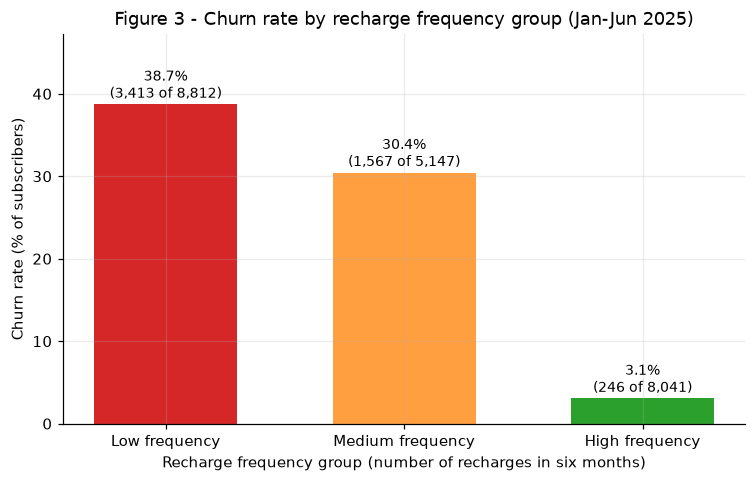

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.6))
colors = ["#d62728", "#ff9f40", "#2ca02c"]
bars = ax.bar(freq_table["frequency_group"].astype(str), freq_table["churn_pct"], color=colors, width=0.6)
for b, (_, row) in zip(bars, freq_table.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8,
            f"{row.churn_pct:.1f}%\n({int(row.churned_subscribers):,} of {int(row.subscribers):,})", ha="center", fontsize=9)
ax.set_ylim(0, freq_table["churn_pct"].max() * 1.22)
ax.set_title("Figure 3 - Churn rate by recharge frequency group (Jan-Jun 2025)")
ax.set_xlabel("Recharge frequency group (number of recharges in six months)")
ax.set_ylabel("Churn rate (% of subscribers)")
save_fig(fig, "fig3_churn_by_frequency.png");

### 6.4 Why this does not prove that more recharging *causes* less churn
An observed association is not a causal effect, for several reasons:
1. **Reverse causality.** Customers who are *about to leave* stop recharging. Low recharge frequency may be a **result** of churn (or of the decision to leave), not its cause. A churned subscriber also has a shorter period in which to recharge (checked in Section 8.3).
2. **Confounding.** Other factors can drive both recharge frequency and churn, for example prepaid vs postpaid connection type, plan, network quality or complaints.
3. **No intervention.** We only *observed* subscribers. To show that increasing recharge frequency lowers churn we would need an experiment (for example a randomised retention offer) or a carefully designed causal analysis.

So the correct statement is: *low recharge frequency is **associated with** much higher churn*, which makes it a useful **warning signal**, but not a proven lever.

## 7. Task 3 – Customer tenure and churn status

- **Research question:** Does mean `tenure_days` differ between churned and retained subscribers?
- **H0:** μ(churned) = μ(retained) | **H1:** μ(churned) ≠ μ(retained) | **Two-tailed**, α = 0.05
- **Why Welch's t-test:** tenure is a numeric variable, the two groups are independent, the group sizes are very different, and the standard deviations are similar but not identical. Welch's test does not need equal variances. We first check the shape of the distribution (box plot, histogram, skewness) and also run Mann-Whitney U as a robustness check.

In [17]:
t3 = welch_report(
    "A7-T3", "Customer tenure (days) by churn status",
    "Does mean tenure (days) differ between churned and retained subscribers?",
    "Mean tenure of churned subscribers = mean tenure of retained subscribers.",
    "Mean tenure of churned subscribers is different from that of retained subscribers.",
    "Tenure is numeric, the groups are independent with unequal sizes, and Welch's test does not assume equal variances; n is large and the tenure distribution is close to symmetric (see below).",
    "Churned", "Retained", churned["tenure_days"], retained["tenure_days"], "days",
    "Churned subscribers have a somewhat shorter tenure on average, but tenure overlaps heavily between the two groups, so on its own it is a weak signal for predicting who will churn.")


#### A7-T3 - Customer tenure (days) by churn status
**Step 1 - Research question and groups.** Does mean tenure (days) differ between churned and retained subscribers?  Groups: **Churned** (n = 5,226) vs **Retained** (n = 16,774).

**Step 2 - Hypotheses.** H0: Mean tenure of churned subscribers = mean tenure of retained subscribers.  |  H1: Mean tenure of churned subscribers is different from that of retained subscribers.

**Step 3 - Test direction.** Two-tailed, because we only ask whether the groups *differ*, in either direction (decided before looking at results).

**Step 4 - Test used.** Welch's independent-samples t-test. Tenure is numeric, the groups are independent with unequal sizes, and Welch's test does not assume equal variances; n is large and the tenure distribution is close to symmetric (see below).

**Step 5 - Descriptive statistics.**


,n,mean,median,std dev,min,max
Churned,"5,226",651.587639,633.000000,328.853758,122.000000,1276.000000
Retained,"16,774",711.879874,720.000000,331.753529,122.000000,1276.000000



**Step 6 - Test statistic and p-value.** t = -11.549, df = 8,788.5, p = 1.24e-30  (Mann-Whitney U robustness check: p = 2.08e-30)

**Step 7 - Decision at α = 0.05.** **Reject H0**

**Step 8 - Difference in original units.** Churned minus Retained = **-60.29 days** (95% CI -70.53 to -50.06); -8.5% relative to the Retained mean.

**Step 9 - Practical importance.** Statistically significant, but the practical size of the difference is negligible (-8.5% relative to Retained, Cohen's d = -0.18). Churned subscribers have a somewhat shorter tenure on average, but tenure overlaps heavily between the two groups, so on its own it is a weak signal for predicting who will churn.


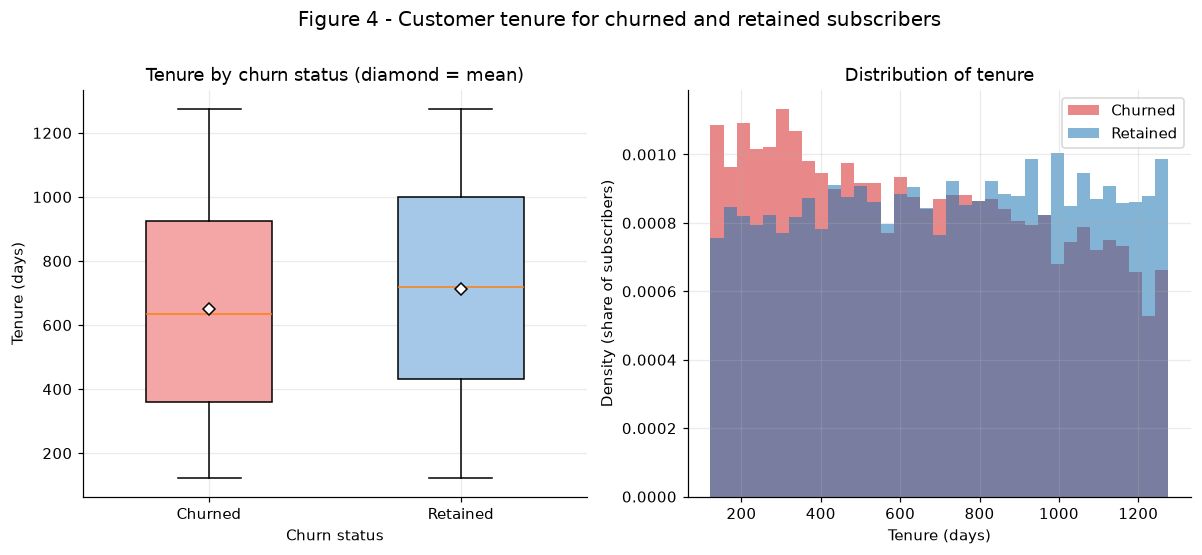

,n,mean,median,std dev,min,Q1,Q3,max,skewness
Churned,"5,226.00",651.59,633.00,328.85,122.00,360.25,926.00,"1,276.00",0.16
Retained,"16,774.00",711.88,720.00,331.75,122.00,431.00,999.00,"1,276.00",-0.04



**Shape of the distributions.** Churned: approximately symmetric (skewness +0.16; mean - median = +18.6 days). Retained: approximately symmetric (skewness -0.04; mean - median = -8.1 days).

**Is the mean enough?** No. The mean gives only the centre. Tenure values range from 122 to 1276 days with a standard deviation of about 332 days, so individual subscribers differ widely from the average. The box plot shows the two groups **overlap heavily**: a mean gap of 60 days is small compared with that spread (Cohen's d = -0.18, negligible). The median, quartiles and range give a fuller picture than the mean alone.


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
bp = axes[0].boxplot([churned["tenure_days"], retained["tenure_days"]], tick_labels=["Churned", "Retained"],
                     showmeans=True, patch_artist=True, widths=0.5,
                     meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black"))
for patch, colr in zip(bp["boxes"], ["#f4a6a6", "#a6c8e8"]):
    patch.set_facecolor(colr)
axes[0].set_title("Tenure by churn status (diamond = mean)")
axes[0].set_xlabel("Churn status"); axes[0].set_ylabel("Tenure (days)")
for lab, g, colr in [("Churned", churned, "#d62728"), ("Retained", retained, "#1f77b4")]:
    axes[1].hist(g["tenure_days"], bins=35, density=True, alpha=0.55, label=lab, color=colr)
axes[1].set_title("Distribution of tenure"); axes[1].set_xlabel("Tenure (days)"); axes[1].set_ylabel("Density (share of subscribers)"); axes[1].legend()
fig.suptitle("Figure 4 - Customer tenure for churned and retained subscribers", y=1.03, fontsize=13)
save_fig(fig, "fig4_tenure_boxplot.png")

def shape_text(s):
    sk = s.skew()
    if abs(sk) < 0.5: kind = "approximately symmetric"
    elif sk > 0:      kind = "moderately right-skewed" if sk < 1 else "strongly right-skewed"
    else:             kind = "moderately left-skewed" if sk > -1 else "strongly left-skewed"
    return f"{kind} (skewness {sk:+.2f}; mean - median = {s.mean() - s.median():+.1f} days)"

shape_table = pd.DataFrame({
    g: {"n": len(s), "mean": s.mean(), "median": s.median(), "std dev": s.std(), "min": s.min(), "Q1": s.quantile(.25),
        "Q3": s.quantile(.75), "max": s.max(), "skewness": s.skew()}
    for g, s in [("Churned", churned["tenure_days"]), ("Retained", retained["tenure_days"])]}).T
display(shape_table)
display(Markdown(f"""
**Shape of the distributions.** Churned: {shape_text(churned['tenure_days'])}. Retained: {shape_text(retained['tenure_days'])}.

**Is the mean enough?** No. The mean gives only the centre. Tenure values range from {int(validation_df.tenure_days.min())} to {int(validation_df.tenure_days.max())} days with a standard deviation of about {validation_df.tenure_days.std():,.0f} days, so individual subscribers differ widely from the average. The box plot shows the two groups **overlap heavily**: a mean gap of {abs(R['A7-T3']['diff']):,.0f} days is small compared with that spread (Cohen's d = {R['A7-T3']['d']:.2f}, {R['A7-T3']['eff']}). The median, quartiles and range give a fuller picture than the mean alone.
"""))

## 8. Task 4 – Robustness and sensitivity check

**Question:** Does the total-recharge conclusion change if we remove subscribers with **zero** recharge transactions?

Why it matters: in the full population, a large share of churned subscribers have a total of 0 (see the '% zeros' column in Section 5.1), and these zeros pull the churned mean down. We therefore repeat Test 1A using **recharge-active subscribers only** (`recharge_count > 0`) and check whether the conclusion changes.

- **H0:** μ(churned) = μ(retained) total recharge among recharge-active subscribers | **H1:** the means differ | **Two-tailed**, α = 0.05

In [19]:
active = validation_df[validation_df["recharge_count"] > 0]
t4 = welch_report(
    "A7-T4", "Total recharge amount, recharge-active subscribers only (robustness check)",
    "Among subscribers with at least one recharge, does mean total recharge amount over six months differ between churned and retained subscribers?",
    "Mean total recharge of churned = mean total recharge of retained (recharge-active subscribers only).",
    "Mean total recharge of churned is different from that of retained (recharge-active subscribers only).",
    "Same reasoning as Test 1A: two independent, skewed groups with unequal sizes and variances but large n. Only the population changes.",
    "Churned (recharged at least once)", "Retained (recharged at least once)", active[active.is_churned == 1]["total_recharge"],
    active[active.is_churned == 0]["total_recharge"], "INR",
    "Even among customers who did recharge, churned subscribers spent less, but the gap is smaller than in the full population.")


#### A7-T4 - Total recharge amount, recharge-active subscribers only (robustness check)
**Step 1 - Research question and groups.** Among subscribers with at least one recharge, does mean total recharge amount over six months differ between churned and retained subscribers?  Groups: **Churned (recharged at least once)** (n = 3,582) vs **Retained (recharged at least once)** (n = 14,707).

**Step 2 - Hypotheses.** H0: Mean total recharge of churned = mean total recharge of retained (recharge-active subscribers only).  |  H1: Mean total recharge of churned is different from that of retained (recharge-active subscribers only).

**Step 3 - Test direction.** Two-tailed, because we only ask whether the groups *differ*, in either direction (decided before looking at results).

**Step 4 - Test used.** Welch's independent-samples t-test. Same reasoning as Test 1A: two independent, skewed groups with unequal sizes and variances but large n. Only the population changes.

**Step 5 - Descriptive statistics.**


,n,mean,median,std dev,min,max
Churned (recharged at least once),"3,582",1354.026801,836.000000,1499.888085,99.000000,10689.000000
Retained (recharged at least once),"14,707",2761.891888,1745.000000,2652.829016,719.000000,10939.000000



**Step 6 - Test statistic and p-value.** t = -42.323, df = 9,739.8, p < 1e-300  (Mann-Whitney U robustness check: p < 1e-300)

**Step 7 - Decision at α = 0.05.** **Reject H0**

**Step 8 - Difference in original units.** Churned (recharged at least once) minus Retained (recharged at least once) = **-1,407.87 INR** (95% CI -1,473.07 to -1,342.66); -51.0% relative to the Retained (recharged at least once) mean.

**Step 9 - Practical importance.** Statistically significant and the practical size is medium (-51.0% relative to Retained (recharged at least once), Cohen's d = -0.57), so it is large enough to matter to the business. Even among customers who did recharge, churned subscribers spent less, but the gap is smaller than in the full population.


### 8.1 Full population vs recharge-active population

,Full population (Test 1A),Recharge-active only (Test 4)
n churned,5226,3582
n retained,16774,14707
mean churned (INR),928.08,"1,354.03"
mean retained (INR),"2,421.55","2,761.89"
median churned (INR),563.00,836.00
median retained (INR),"1,495.00","1,745.00"
difference in means (INR),"-1,493.48","-1,407.87"
relative difference (%),-61.67,-50.97
Welch t,-53.21,-42.32
p-value,< 1e-300,< 1e-300


,before filter,after filter,removed,% removed
status,,,,
Churned,5226,3582,1644,31.46
Retained,16774,14707,2067,12.32



**Sample sizes.** Filtering removed **1,644** churned subscribers (31.5% of that group) and **2,067** retained subscribers (12.3%). The churned group lost a much larger share of its members.

**Group averages.** Mean total recharge: churned 928 → 1,354 INR, retained 2,422 → 2,762 INR (both averages rise because the zeros are removed). The absolute gap goes from -1,493 to -1,408 INR (5.7% smaller in size), the relative gap from -61.7% to -51.0%, and Cohen's d from -0.62 (medium) to -0.57 (medium).

**Statistical conclusion.** Full population: *Reject H0* (p < 1e-300). Recharge-active population: *Reject H0* (p < 1e-300). The **decision does not change** at α = 0.05, and the absolute gap barely changes. So the finding that churned subscribers recharge less in total is **robust** to removing zero-recharge subscribers; what shrinks is the *relative* gap, because the retained group's mean rises more in proportion once zero-recharge subscribers are removed.

**Why the population definition matters.** "Recharge behaviour" mixes two questions: *whether* a subscriber recharges at all, and *how much* they spend when they do. The full population answers both together; the recharge-active population answers only the second. Filtering changes the sample sizes, every group mean and the relative gap, and because the filter removes churned subscribers at a much higher rate than retained ones, the two groups are not affected equally. We could only know that the conclusion holds by checking it. Every result should therefore state which population it describes.


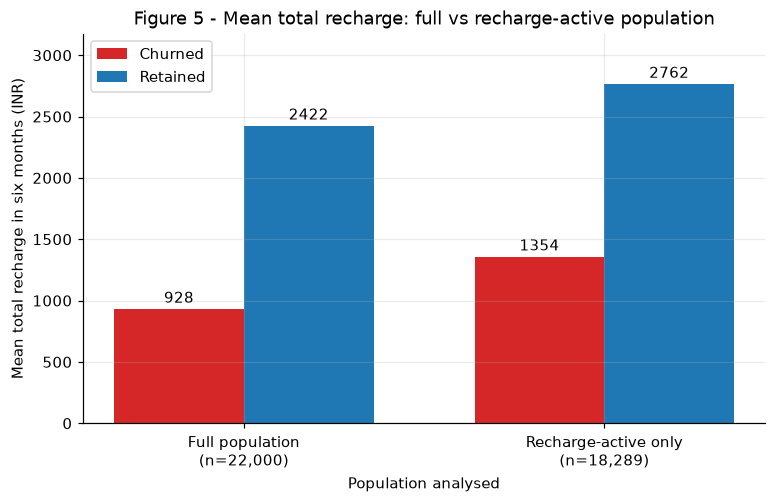

In [20]:
full, act = R["A7-T1a"], R["A7-T4"]
n_before = validation_df.groupby("status").size()
n_after  = active.groupby("status").size()
compare = pd.DataFrame({
    "Full population (Test 1A)": {
        "n churned": full["n1"], "n retained": full["n2"],
        "mean churned (INR)": full["m1"], "mean retained (INR)": full["m2"],
        "median churned (INR)": full["med1"], "median retained (INR)": full["med2"],
        "difference in means (INR)": full["diff"], "relative difference (%)": full["rel"],
        "Welch t": full["stat"], "p-value": fmt_p(full["p"]), "Cohen's d": full["d"], "decision": full["decision"]},
    "Recharge-active only (Test 4)": {
        "n churned": act["n1"], "n retained": act["n2"],
        "mean churned (INR)": act["m1"], "mean retained (INR)": act["m2"],
        "median churned (INR)": act["med1"], "median retained (INR)": act["med2"],
        "difference in means (INR)": act["diff"], "relative difference (%)": act["rel"],
        "Welch t": act["stat"], "p-value": fmt_p(act["p"]), "Cohen's d": act["d"], "decision": act["decision"]}})
display(compare)

removed = pd.DataFrame({"before filter": n_before, "after filter": n_after, "removed": n_before - n_after})
removed["% removed"] = removed["removed"] / removed["before filter"] * 100
display(removed)

same = full["decision"] == act["decision"]
gap_chg = (act["diff"] - full["diff"]) / abs(full["diff"]) * 100          # % change in the absolute gap
size_word = "barely changes" if abs(gap_chg) < 10 else "changes noticeably"
display(Markdown(f"""
**Sample sizes.** Filtering removed **{int(removed.loc['Churned','removed']):,}** churned subscribers ({removed.loc['Churned','% removed']:.1f}% of that group) and **{int(removed.loc['Retained','removed']):,}** retained subscribers ({removed.loc['Retained','% removed']:.1f}%). The churned group lost a much larger share of its members.

**Group averages.** Mean total recharge: churned {full['m1']:,.0f} → {act['m1']:,.0f} INR, retained {full['m2']:,.0f} → {act['m2']:,.0f} INR (both averages rise because the zeros are removed). The absolute gap goes from {full['diff']:,.0f} to {act['diff']:,.0f} INR ({abs(gap_chg):.1f}% {'smaller' if gap_chg > 0 else 'larger'} in size), the relative gap from {full['rel']:.1f}% to {act['rel']:.1f}%, and Cohen's d from {full['d']:.2f} ({full['eff']}) to {act['d']:.2f} ({act['eff']}).

**Statistical conclusion.** Full population: *{full['decision']}* ({p_eq(full['p'])}). Recharge-active population: *{act['decision']}* ({p_eq(act['p'])}). The **decision {'does not change' if same else 'changes'}** at α = {ALPHA}, and the absolute gap {size_word}. So the finding that churned subscribers recharge less in total is **robust** to removing zero-recharge subscribers; what shrinks is the *relative* gap, because the retained group's mean rises more in proportion once zero-recharge subscribers are removed.

**Why the population definition matters.** "Recharge behaviour" mixes two questions: *whether* a subscriber recharges at all, and *how much* they spend when they do. The full population answers both together; the recharge-active population answers only the second. Filtering changes the sample sizes, every group mean and the relative gap, and because the filter removes churned subscribers at a much higher rate than retained ones, the two groups are not affected equally. We could only know that the conclusion holds by checking it. Every result should therefore state which population it describes.
"""))

fig, ax = plt.subplots(figsize=(8, 4.6))
x = np.arange(2); w = 0.36
b1 = ax.bar(x - w / 2, [full["m1"], act["m1"]], w, label="Churned", color="#d62728")
b2 = ax.bar(x + w / 2, [full["m2"], act["m2"]], w, label="Retained", color="#1f77b4")
ax.bar_label(b1, fmt="%.0f", padding=2); ax.bar_label(b2, fmt="%.0f", padding=2)
ax.set_xticks(x); ax.set_xticklabels([f"Full population\n(n={full['n1']+full['n2']:,})", f"Recharge-active only\n(n={act['n1']+act['n2']:,})"])
ax.set_title("Figure 5 - Mean total recharge: full vs recharge-active population")
ax.set_xlabel("Population analysed"); ax.set_ylabel("Mean total recharge in six months (INR)")
ax.set_ylim(0, max(full["m2"], act["m2"]) * 1.15); ax.legend()
save_fig(fig, "fig5_robustness.png");

### 8.2 Supplementary check – does connection type (prepaid / postpaid) explain the result?
`connection_type` is related to both recharge amounts and churn, so it is a possible **confounder**. As a sensitivity check we repeat the total-recharge test **inside** each connection type. We also repeat the Low-vs-High frequency churn test inside each connection type. These are *supplementary* tests: they are shown in a separate sheet in the Excel file and are not part of the six required tests.

In [21]:
by_type = validation_df.groupby("connection_type").agg(
    subscribers=("customer_id", "count"), churn_pct=("is_churned", lambda s: s.mean() * 100),
    mean_total_recharge=("total_recharge", "mean"), mean_recharge_count=("recharge_count", "mean"),
    pct_low_frequency=("frequency_group", lambda s: (s == "Low frequency").mean() * 100),
    pct_high_frequency=("frequency_group", lambda s: (s == "High frequency").mean() * 100))
display(by_type)

for ctype in ["Prepaid", "Postpaid"]:
    sub = validation_df[validation_df.connection_type == ctype]
    welch_report(f"A7-S-{ctype}", f"Supplementary: total recharge within {ctype} subscribers",
        f"Within {ctype} subscribers, does mean total recharge over six months differ between churned and retained subscribers?",
        "Mean total recharge of churned = mean total recharge of retained.",
        "Mean total recharge of churned is different from that of retained.",
        "Same Welch test as Test 1A but restricted to one connection type to reduce confounding by connection type.",
        "Churned", "Retained", sub[sub.is_churned == 1]["total_recharge"], sub[sub.is_churned == 0]["total_recharge"], "INR",
        f"Checks whether the main result still holds inside {ctype} subscribers only.", supplementary=True)

for ctype in ["Prepaid", "Postpaid"]:
    sub = validation_df[validation_df.connection_type == ctype]
    lo = sub[sub.frequency_group == "Low frequency"]; hi = sub[sub.frequency_group == "High frequency"]
    prop_result(f"A7-S-Freq-{ctype}", f"Supplementary: within {ctype} subscribers, is the churn rate of Low-frequency subscribers different from High-frequency subscribers?",
        "Low frequency (0-2 recharges)", "High frequency (6+ recharges)", int(lo.is_churned.sum()), len(lo), int(hi.is_churned.sum()), len(hi),
        "Churn proportion of Low-frequency = churn proportion of High-frequency (within this connection type).",
        "Churn proportion of Low-frequency is different from that of High-frequency (within this connection type).",
        f"Checks whether the frequency-churn association holds inside {ctype} subscribers only.", supplementary=True)
sfreq = pd.DataFrame([{"Test ID": R[k]["id"], "Group": k.split("-")[-1], "Low-freq churn %": R[k]["m1"], "High-freq churn %": R[k]["m2"],
                       "Difference (pp)": R[k]["diff"], "z": R[k]["stat"], "p-value": fmt_p(R[k]["p"]), "Decision": R[k]["decision"]}
                      for k in ["A7-S-Freq-Prepaid", "A7-S-Freq-Postpaid"]])
display(sfreq)

,subscribers,churn_pct,mean_total_recharge,mean_recharge_count,pct_low_frequency,pct_high_frequency
connection_type,,,,,,
Postpaid,4851,16.18,"5,822.51",5.39,6.62,74.52
Prepaid,17149,25.90,"1,004.39",3.36,49.51,25.81



#### A7-S-Prepaid - Supplementary: total recharge within Prepaid subscribers
**Step 1 - Research question and groups.** Within Prepaid subscribers, does mean total recharge over six months differ between churned and retained subscribers?  Groups: **Churned** (n = 4,441) vs **Retained** (n = 12,708).

**Step 2 - Hypotheses.** H0: Mean total recharge of churned = mean total recharge of retained.  |  H1: Mean total recharge of churned is different from that of retained.

**Step 3 - Test direction.** Two-tailed, because we only ask whether the groups *differ*, in either direction (decided before looking at results).

**Step 4 - Test used.** Welch's independent-samples t-test. Same Welch test as Test 1A but restricted to one connection type to reduce confounding by connection type.

**Step 5 - Descriptive statistics.**


,n,mean,median,std dev,min,max
Churned,"4,441",521.817158,418.000000,541.553864,0.000000,2394.000000
Retained,"12,708",1173.031870,1188.000000,698.914333,0.000000,2394.000000



**Step 6 - Test statistic and p-value.** t = -63.711, df = 9,936.6, p < 1e-300  (Mann-Whitney U robustness check: p < 1e-300)

**Step 7 - Decision at α = 0.05.** **Reject H0**

**Step 8 - Difference in original units.** Churned minus Retained = **-651.21 INR** (95% CI -671.25 to -631.18); -55.5% relative to the Retained mean.

**Step 9 - Practical importance.** Statistically significant and the practical size is large (-55.5% relative to Retained, Cohen's d = -0.98), so it is large enough to matter to the business. Checks whether the main result still holds inside Prepaid subscribers only.



#### A7-S-Postpaid - Supplementary: total recharge within Postpaid subscribers
**Step 1 - Research question and groups.** Within Postpaid subscribers, does mean total recharge over six months differ between churned and retained subscribers?  Groups: **Churned** (n = 785) vs **Retained** (n = 4,066).

**Step 2 - Hypotheses.** H0: Mean total recharge of churned = mean total recharge of retained.  |  H1: Mean total recharge of churned is different from that of retained.

**Step 3 - Test direction.** Two-tailed, because we only ask whether the groups *differ*, in either direction (decided before looking at results).

**Step 4 - Test used.** Welch's independent-samples t-test. Same Welch test as Test 1A but restricted to one connection type to reduce confounding by connection type.

**Step 5 - Descriptive statistics.**


,n,mean,median,std dev,min,max
Churned,785,3226.412739,2731.000000,2241.816383,0.000000,10689.000000
Retained,"4,066",6323.722332,6497.500000,2688.805888,1764.000000,10939.000000



**Step 6 - Test statistic and p-value.** t = -34.245, df = 1,261.2, p = 2.87e-182  (Mann-Whitney U robustness check: p = 9.51e-171)

**Step 7 - Decision at α = 0.05.** **Reject H0**

**Step 8 - Difference in original units.** Churned minus Retained = **-3,097.31 INR** (95% CI -3,274.75 to -2,919.87); -49.0% relative to the Retained mean.

**Step 9 - Practical importance.** Statistically significant and the practical size is large (-49.0% relative to Retained, Cohen's d = -1.18), so it is large enough to matter to the business. Checks whether the main result still holds inside Postpaid subscribers only.


,Test ID,Group,Low-freq churn %,High-freq churn %,Difference (pp),z,p-value,Decision
0,A7-S-Freq-Prepaid,Prepaid,36.42,4.93,31.49,38.91,< 1e-300,Reject H0
1,A7-S-Freq-Postpaid,Postpaid,100.00,0.77,99.23,59.93,< 1e-300,Reject H0


### 8.3 Supplementary checks and limitations of the analysis
Some limitations can be checked with the data. We measure them here so that the statements in the conclusion are evidence-based.

In [22]:
# (a) Unequal exposure: churned subscribers leave part-way through the period, so they have fewer days to recharge
expo = q("SELECT customer_id, is_churned, churn_date FROM customer_features")
expo["churn_date"] = pd.to_datetime(expo["churn_date"])
last_day = pd.Timestamp(END) - pd.Timedelta(days=1)
expo["observed_days"] = np.where(expo["is_churned"] == 1, (expo["churn_date"] - pd.Timestamp(START)).dt.days + 1, OBS_DAYS)
expo_summary = expo.groupby("is_churned")["observed_days"].agg(["mean", "median", "min", "max"]).rename(index={0: "Retained", 1: "Churned"})
display(expo_summary)
after_churn = q("""SELECT COUNT(*) AS n FROM recharges r JOIN customer_features cf USING (customer_id)
                   WHERE cf.is_churned = 1 AND r.recharge_date > cf.churn_date AND r.recharge_date >= :s AND r.recharge_date < :e""",
                {"s": START, "e": END})["n"][0]
print("Recharges recorded after a subscriber's churn date:", after_churn)

# (b) Skew of the recharge measures (all subscribers)
skew_tbl = validation_df[["total_recharge", "recharge_count", "average_recharge"]].skew().rename("skewness")
display(skew_tbl.to_frame())

# (c) Mixed transaction types
print(f"Share of in-period transactions that are 'Bill Payment': {bill_share:.1f}%")
bill_by_type = q("""SELECT cf.connection_type, r.txn_type, COUNT(*) AS transactions, ROUND(AVG(r.amount_inr),1) AS avg_amount
                    FROM recharges r JOIN customer_features cf USING (customer_id)
                    WHERE r.recharge_date >= :s AND r.recharge_date < :e GROUP BY 1,2 ORDER BY 1,2""", {"s": START, "e": END})
display(bill_by_type)

,mean,median,min,max
is_churned,,,,
Retained,181.00,181.00,181.00,181.00
Churned,96.60,97.00,16.00,174.00


Recharges recorded after a subscriber's churn date: 0


,skewness
total_recharge,2.01
recharge_count,0.44
average_recharge,1.45


Share of in-period transactions that are 'Bill Payment': 31.3%


,connection_type,txn_type,transactions,avg_amount
0,Postpaid,Bill Payment,26156,"1,079.90"
1,Prepaid,Recharge,57537,299.40


**Limitations (summary)**
1. **Observational data.** Subscribers were not randomly assigned to recharge more or less. We can describe associations only, never causes.
2. **Confounding.** Connection type, plan and complaints can influence both recharging and churning. The supplementary test above shows the conclusion within each connection type, but other confounders remain unmeasured.
3. **Reverse causality and unequal exposure.** Churned subscribers are observed for fewer days (table above), so they have less time to recharge. Part of the gap is built into the way churn is defined.
4. **Mixed transaction types.** The `recharges` table contains both prepaid recharges and postpaid bill payments, with very different amounts. We followed the assignment definition and kept both types.
5. **Skewed, zero-heavy recharge values.** Means are pulled by large values and by many zeros; we report medians and a Mann-Whitney check next to every Welch test.
6. **Limited observation period.** Six months may miss seasonal or longer-term behaviour.
7. **Many tests.** Six required tests are run at α = 0.05 each. All main p-values are far below even a stricter Bonferroni limit of 0.05/6 ≈ 0.0083 (see the summary table), so this does not change the decisions.
8. **Large samples make tiny differences significant.** With thousands of subscribers per group, even small differences can have small p-values, which is why effect sizes and original units are reported.

## 9. Results summary

One row per statistical test, in the column layout required for the Excel file. The Excel workbook `reports/07_Validation_Summary.xlsx` is produced from this table by the cell below.

In [23]:
MAIN_IDS = ["A7-T1a", "A7-T1b", "A7-T1c", "A7-T2", "A7-T3", "A7-T4"]
SUPP_IDS = ["A7-S-Prepaid", "A7-S-Postpaid", "A7-S-Freq-Prepaid", "A7-S-Freq-Postpaid"]

def to_row(r):
    return {"Test ID": r["id"], "Research Question": r["rq"], "Group 1": r["g1"], "Group 2": r["g2"],
            "Sample Size 1": r["n1"], "Sample Size 2": r["n2"], "Group Values": r["group_values"], "Difference": r["diff_text"],
            "Test Used": r["test"], "Test Statistic": round(float(r["stat"]), 4), "p-value": p_cell(r["p"]),
            "Significance Level": ALPHA, "Decision": r["decision"], "Business Interpretation": r["interp"],
            "Degrees of Freedom": (round(float(r["df"]), 1) if r["df"] is not None else "n/a"),
            "Null Hypothesis (H0)": r["h0"], "Alternative Hypothesis (H1)": r["h1"], "Test Direction": r["direction"],
            "Effect Size": r["effect_text"]}

summary_df = pd.DataFrame([to_row(R[i]) for i in MAIN_IDS])
supp_df    = pd.DataFrame([to_row(R[i]) for i in SUPP_IDS])

display_cols = summary_df[["Test ID", "Group 1", "Group 2", "Sample Size 1", "Sample Size 2", "Test Statistic", "Decision"]].copy()
display_cols["p-value"] = [fmt_p(R[i]["p"]) for i in MAIN_IDS]
display_cols["Difference"] = [R[i]["diff_text"].split(";")[0] for i in MAIN_IDS]
display_cols["Effect size"] = [R[i]["effect_text"] for i in MAIN_IDS]
display(display_cols[["Test ID", "Group 1", "Group 2", "Sample Size 1", "Sample Size 2", "Difference", "Test Statistic", "p-value", "Decision", "Effect size"]])
print("Bonferroni-style check: all main p-values below", round(ALPHA / len(MAIN_IDS), 4), "->", all(R[i]["p"] < ALPHA / len(MAIN_IDS) for i in MAIN_IDS))

,Test ID,Group 1,Group 2,Sample Size 1,Sample Size 2,Difference,Test Statistic,p-value,Decision,Effect size
0,A7-T1a,Churned,Retained,5226,16774,"-1,493.48 INR (Churned minus Retained)",-53.21,< 1e-300,Reject H0,Cohen's d = -0.620 (medium)
1,A7-T1b,Churned,Retained,5226,16774,-2.35 transactions (Churned minus Retained),-64.18,< 1e-300,Reject H0,Cohen's d = -0.885 (large)
2,A7-T1c,Churned,Retained,3582,14707,-78.15 INR per transaction (Churned minus Reta...,-9.82,1.39e-22,Reject H0,Cohen's d = -0.182 (negligible)
3,A7-T2,Low frequency (0-2 recharges),High frequency (6+ recharges),8812,8041,+35.67 percentage points (Low frequency (0-2 r...,56.10,< 1e-300,Reject H0,Cohen's h = 0.992 (large); risk ratio = 12.66
4,A7-T3,Churned,Retained,5226,16774,-60.29 days (Churned minus Retained),-11.55,1.24e-30,Reject H0,Cohen's d = -0.182 (negligible)
5,A7-T4,Churned (recharged at least once),Retained (recharged at least once),3582,14707,"-1,407.87 INR (Churned (recharged at least onc...",-42.32,< 1e-300,Reject H0,Cohen's d = -0.570 (medium)


Bonferroni-style check: all main p-values below 0.0083 -> True


In [26]:
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

XLSX_PATH = REPORTS / "07_Validation_Summary.xlsx"
freq_out = freq_table.rename(columns={"frequency_group": "Frequency group", "min_count": "Min recharges", "max_count": "Max recharges",
                                      "subscribers": "Subscribers", "churned_subscribers": "Churned subscribers", "churn_pct": "Churn %"}).copy()
freq_out["Frequency group"] = freq_out["Frequency group"].astype(str)
notes = pd.DataFrame({"Item": ["Purpose", "Data source", "Analysis period", "Unit of analysis", "Significance level", "Test direction",
                               "Group 1 / Group 2", "Difference", "p-value display", "Decision wording", "Supplementary sheet", "Prepared by"],
                      "Detail": ["Statistical validation: is recharge behaviour associated with churn? (Assignment 07)",
                                 "airtel.db: tables customer_features and recharges",
                                 "1 Jan 2025 to 30 Jun 2025 (recharge_date >= '2025-01-01' AND recharge_date < '2025-07-01')",
                                 f"One row per subscriber ({len(validation_df):,} subscribers, LEFT JOIN keeps subscribers with no recharges)",
                                 f"alpha = {ALPHA} for every test", "Two-tailed for every test",
                                 "Group 1 = Churned (or Low frequency in A7-T2); Group 2 = Retained (or High frequency in A7-T2)",
                                 "Group 1 minus Group 2, in the original unit (INR, transactions, days or percentage points)",
                                 "Very small p-values are shown as '< 1e-300' (never as 0)",
                                 "'Reject H0' or 'Fail to reject H0' (never 'Accept H0')",
                                 "A7-S tests are sensitivity checks inside prepaid / postpaid; they are not part of the six required tests",
                                 "Values are computed by notebooks/07_Validation.ipynb (nothing typed in by hand)"]})

with pd.ExcelWriter(XLSX_PATH, engine="openpyxl") as xw:
    summary_df.to_excel(xw, sheet_name="Test Summary", index=False)
    supp_df.to_excel(xw, sheet_name="Supplementary Checks", index=False)
    freq_out.to_excel(xw, sheet_name="Frequency Table", index=False)
    dq_summary.to_excel(xw, sheet_name="Data Quality", index=False)
    notes.to_excel(xw, sheet_name="Notes", index=False)

wb = load_workbook(XLSX_PATH)
thin = Side(style="thin", color="BFBFBF")
for ws in wb.worksheets:
    for cell in ws[1]:
        cell.font = Font(name="Arial", bold=True, color="FFFFFF", size=10)
        cell.fill = PatternFill("solid", fgColor="1F4E79")
        cell.alignment = Alignment(wrap_text=True, vertical="center", horizontal="center")
    for row in ws.iter_rows(min_row=2):
        for cell in row:
            cell.font = Font(name="Arial", size=10)
            cell.alignment = Alignment(wrap_text=True, vertical="top")
            cell.border = Border(top=thin, bottom=thin, left=thin, right=thin)
    ws.freeze_panes = "B2" if ws.title in ("Test Summary", "Supplementary Checks") else "A2"
    ws.row_dimensions[1].height = 32
    for i, col in enumerate(ws.columns, start=1):
        header = str(col[0].value)
        longest = max(len(str(c.value)) if c.value is not None else 0 for c in col)
        ws.column_dimensions[get_column_letter(i)].width = min(max(12, len(header) + 2, longest * 0.55), 60)

for ws in (wb["Test Summary"], wb["Supplementary Checks"]):
    hdr = {c.value: c.column for c in ws[1]}
    for r in range(2, ws.max_row + 1):
        pc = ws.cell(r, hdr["p-value"])
        if isinstance(pc.value, float):
            pc.number_format = "0.0000" if pc.value >= 0.0001 else "0.00E+00"
        ws.cell(r, hdr["Significance Level"]).number_format = "0.00"
        ws.cell(r, hdr["Test Statistic"]).number_format = "0.000"
        ws.cell(r, hdr["Sample Size 1"]).number_format = "#,##0"
        ws.cell(r, hdr["Sample Size 2"]).number_format = "#,##0"
        for name in ("Research Question", "Group Values", "Business Interpretation", "Difference"):
            ws.cell(r, hdr[name]).alignment = Alignment(wrap_text=True, vertical="top")
        ws.row_dimensions[r].height = 150
    for name, wdt in {"Research Question": 38, "Group Values": 48, "Business Interpretation": 60, "Difference": 34,
                      "Null Hypothesis (H0)": 34, "Alternative Hypothesis (H1)": 34, "Test Used": 26, "Group 1": 20, "Group 2": 20}.items():
        ws.column_dimensions[get_column_letter(hdr[name])].width = wdt
wb["Notes"].column_dimensions["B"].width = 100
for r in range(2, wb["Frequency Table"].max_row + 1):
    wb["Frequency Table"].cell(r, 6).number_format = "0.00"
wb.save(XLSX_PATH)

check = pd.read_excel(XLSX_PATH, sheet_name="Test Summary")
required = ["Test ID", "Research Question", "Group 1", "Group 2", "Sample Size 1", "Sample Size 2", "Group Values", "Difference",
            "Test Used", "Test Statistic", "p-value", "Significance Level", "Decision", "Business Interpretation"]
assert all(col in check.columns for col in required) and len(check) == 6
print("Saved:", XLSX_PATH, "| sheets:", load_workbook(XLSX_PATH).sheetnames, "| rows in Test Summary:", len(check))

Saved: c:\Users\dbila\Desktop\airtel-telecom-analytics\reports\07_Validation_Summary.xlsx | sheets: ['Test Summary', 'Supplementary Checks', 'Frequency Table', 'Data Quality', 'Notes'] | rows in Test Summary: 6


## 10. Business conclusion

The text below is generated from the computed results, so it always matches the numbers in the tables above.

In [27]:
a, b, c_, f, t, r4 = (R[k] for k in MAIN_IDS)
prep = by_type.loc["Prepaid"]; post = by_type.loc["Postpaid"]
sP, sQ = R["A7-S-Prepaid"], R["A7-S-Postpaid"]
sF1, sF2 = R["A7-S-Freq-Prepaid"], R["A7-S-Freq-Postpaid"]
gap_chg = (r4["diff"] - a["diff"]) / abs(a["diff"]) * 100
med = freq_table.set_index("frequency_group").loc["Medium frequency"]
low_prepaid_n = int(((validation_df.frequency_group == "Low frequency") & (validation_df.connection_type == "Prepaid")).sum())
low_n = int((validation_df.frequency_group == "Low frequency").sum())
exp_c, exp_r = expo_summary.loc["Churned", "mean"], expo_summary.loc["Retained", "mean"]
fmtp = lambda r: p_eq(r["p"])

findings = [
 f"**Total recharge.** Churned subscribers recharged a mean of {a['m1']:,.0f} INR (median {a['med1']:,.0f}) versus {a['m2']:,.0f} INR (median {a['med2']:,.0f}) for retained subscribers: a difference of {a['diff']:,.0f} INR ({a['rel']:.1f}%). {a['decision']} ({fmtp(a)}); effect size {a['eff']} (d = {a['d']:.2f}).",
 f"**Recharge frequency.** Churned subscribers made {b['m1']:.1f} recharges on average versus {b['m2']:.1f} for retained subscribers ({b['diff']:+.1f}). {b['decision']} ({fmtp(b)}); effect size {b['eff']} (d = {b['d']:.2f}).",
 f"**Average recharge per transaction.** Among recharge-active subscribers the means were {c_['m1']:,.0f} INR (churned) and {c_['m2']:,.0f} INR (retained), a difference of {c_['diff']:,.0f} INR. {c_['decision']} ({fmtp(c_)}), but the effect size is only {c_['eff']} (d = {c_['d']:.2f}). Statistically significant does not mean large.",
 f"**Churn rate by frequency.** Churn was {freq_table.loc[0,'churn_pct']:.1f}% for Low, {freq_table.loc[1,'churn_pct']:.1f}% for Medium and {freq_table.loc[2,'churn_pct']:.1f}% for High-frequency subscribers. Low vs High: {f['diff']:+.1f} percentage points, z = {f['stat']:.1f}, {fmtp(f)}, {f['decision']}; effect size {f['eff']}.",
 f"**Tenure.** Mean tenure was {t['m1']:,.0f} days (churned) versus {t['m2']:,.0f} days (retained), a gap of {abs(t['diff']):,.0f} days. {t['decision']} ({fmtp(t)}), but the effect size is {t['eff']} (d = {t['d']:.2f}) and the groups overlap heavily.",
 f"**Robustness.** After removing {int(removed['removed'].sum()):,} subscribers with no recharges, the absolute total-recharge gap changed from {a['diff']:,.0f} to {r4['diff']:,.0f} INR ({abs(gap_chg):.1f}% {'smaller' if gap_chg > 0 else 'larger'} in size), the relative gap from {a['rel']:.1f}% to {r4['rel']:.1f}%, and d from {a['d']:.2f} to {r4['d']:.2f}. The decision is *{r4['decision']}* in both populations, so the conclusion is robust, although the relative gap is smaller.",
]
display(Markdown("### Findings\n" + "\n".join(f"{i}. {x}" for i, x in enumerate(findings, 1))))

recs = [
 f"**Use recharge frequency as an early-warning signal.** Subscribers with 0-2 recharges in a six-month window ({low_n:,} subscribers) churned at {freq_table.loc[0,'churn_pct']:.1f}%. Build a monthly watch-list of subscribers whose recharge frequency is falling.",
 f"**Focus first on prepaid low-frequency subscribers.** {low_prepaid_n:,} of the {low_n:,} low-frequency subscribers are prepaid. Prepaid churn is {prep['churn_pct']:.1f}% versus {post['churn_pct']:.1f}% for postpaid.",
 "**Test before scaling.** Because the data are observational, run a small randomised pilot (for example a recharge reminder or a bonus for a second recharge) and compare churn with a control group before claiming that more recharging reduces churn.",
 f"**Do not rely on tenure alone.** The tenure difference is statistically significant but {t['eff']} in size, so it is a weak targeting variable by itself.",
 "**Report medians and state the population.** Recharge values are skewed and many subscribers have zero recharges, so every future report should show the median and say whether zero-recharge subscribers are included.",
 "**Next analysis.** Fit a logistic regression with recharge frequency, connection type, tenure and complaints together, using a recharge window that ends *before* the churn date, to separate the effects and reduce reverse causality.",
]
display(Markdown("### Recommendations\n" + "\n".join(f"{i}. {x}" for i, x in enumerate(recs, 1))))

lims = [
 "**Observational data and no causal claim.** The results describe association only.",
 f"**Possible confounding.** Prepaid and postpaid subscribers differ greatly in churn ({prep['churn_pct']:.1f}% vs {post['churn_pct']:.1f}%) and in mean total recharge ({prep['mean_total_recharge']:,.0f} vs {post['mean_total_recharge']:,.0f} INR). Within each connection type the total-recharge result is: Prepaid {sP['decision']} ({fmtp(sP)}, d = {sP['d']:.2f}), Postpaid {sQ['decision']} ({fmtp(sQ)}, d = {sQ['d']:.2f}). Frequency groups also differ by connection type: {post['pct_high_frequency']:.0f}% of postpaid subscribers are High-frequency versus {prep['pct_high_frequency']:.0f}% of prepaid (postpaid subscribers pay regular bills, see the transaction-type table). Within each type the Low-vs-High churn gap is {sF1['diff']:+.1f} pp for Prepaid and {sF2['diff']:+.1f} pp for Postpaid (both {sF1['decision'] if sF1['decision']==sF2['decision'] else 'mixed'}).",
 f"**Unequal exposure / reverse causality.** Churned subscribers were observed for only {exp_c:.0f} days on average in the period, compared with {exp_r:.0f} days for retained subscribers, so they had less time to recharge.",
 f"**Mixed transaction types.** {bill_share:.1f}% of in-period transactions are bill payments (larger amounts), which are mixed with prepaid recharges as defined in the assignment.",
 "**Skewed recharge values.** Means are affected by extreme values and zeros, so medians and Mann-Whitney checks were reported alongside.",
 "**Limited observation period.** Six months cannot capture seasonal or long-term patterns.",
]
display(Markdown("### Limitations\n" + "\n".join(f"{i}. {x}" for i, x in enumerate(lims, 1))))

### Findings
1. **Total recharge.** Churned subscribers recharged a mean of 928 INR (median 563) versus 2,422 INR (median 1,495) for retained subscribers: a difference of -1,493 INR (-61.7%). Reject H0 (p < 1e-300); effect size medium (d = -0.62).
2. **Recharge frequency.** Churned subscribers made 2.0 recharges on average versus 4.4 for retained subscribers (-2.3). Reject H0 (p < 1e-300); effect size large (d = -0.88).
3. **Average recharge per transaction.** Among recharge-active subscribers the means were 515 INR (churned) and 594 INR (retained), a difference of -78 INR. Reject H0 (p = 1.39e-22), but the effect size is only negligible (d = -0.18). Statistically significant does not mean large.
4. **Churn rate by frequency.** Churn was 38.7% for Low, 30.4% for Medium and 3.1% for High-frequency subscribers. Low vs High: +35.7 percentage points, z = 56.1, p < 1e-300, Reject H0; effect size large.
5. **Tenure.** Mean tenure was 652 days (churned) versus 712 days (retained), a gap of 60 days. Reject H0 (p = 1.24e-30), but the effect size is negligible (d = -0.18) and the groups overlap heavily.
6. **Robustness.** After removing 3,711 subscribers with no recharges, the absolute total-recharge gap changed from -1,493 to -1,408 INR (5.7% smaller in size), the relative gap from -61.7% to -51.0%, and d from -0.62 to -0.57. The decision is *Reject H0* in both populations, so the conclusion is robust, although the relative gap is smaller.

### Recommendations
1. **Use recharge frequency as an early-warning signal.** Subscribers with 0-2 recharges in a six-month window (8,812 subscribers) churned at 38.7%. Build a monthly watch-list of subscribers whose recharge frequency is falling.
2. **Focus first on prepaid low-frequency subscribers.** 8,491 of the 8,812 low-frequency subscribers are prepaid. Prepaid churn is 25.9% versus 16.2% for postpaid.
3. **Test before scaling.** Because the data are observational, run a small randomised pilot (for example a recharge reminder or a bonus for a second recharge) and compare churn with a control group before claiming that more recharging reduces churn.
4. **Do not rely on tenure alone.** The tenure difference is statistically significant but negligible in size, so it is a weak targeting variable by itself.
5. **Report medians and state the population.** Recharge values are skewed and many subscribers have zero recharges, so every future report should show the median and say whether zero-recharge subscribers are included.
6. **Next analysis.** Fit a logistic regression with recharge frequency, connection type, tenure and complaints together, using a recharge window that ends *before* the churn date, to separate the effects and reduce reverse causality.

### Limitations
1. **Observational data and no causal claim.** The results describe association only.
2. **Possible confounding.** Prepaid and postpaid subscribers differ greatly in churn (25.9% vs 16.2%) and in mean total recharge (1,004 vs 5,823 INR). Within each connection type the total-recharge result is: Prepaid Reject H0 (p < 1e-300, d = -0.98), Postpaid Reject H0 (p = 2.87e-182, d = -1.18). Frequency groups also differ by connection type: 75% of postpaid subscribers are High-frequency versus 26% of prepaid (postpaid subscribers pay regular bills, see the transaction-type table). Within each type the Low-vs-High churn gap is +31.5 pp for Prepaid and +99.2 pp for Postpaid (both Reject H0).
3. **Unequal exposure / reverse causality.** Churned subscribers were observed for only 97 days on average in the period, compared with 181 days for retained subscribers, so they had less time to recharge.
4. **Mixed transaction types.** 31.3% of in-period transactions are bill payments (larger amounts), which are mixed with prepaid recharges as defined in the assignment.
5. **Skewed recharge values.** Means are affected by extreme values and zeros, so medians and Mann-Whitney checks were reported alongside.
6. **Limited observation period.** Six months cannot capture seasonal or long-term patterns.

### 10.1 Export the business report (PDF)
The cell below builds `reports/07_Validation_Conclusion.pdf` (2–4 pages) from the results and figures computed above.

In [28]:
from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.lib.units import cm
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_LEFT
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, PageBreak, KeepTogether
from PIL import Image as PILImage
import re

PDF_PATH = REPORTS / "07_Validation_Conclusion.pdf"

def safe(s):
    """Make text safe for the built-in PDF font and for reportlab markup."""
    s = (s.replace("\u20b9", "INR").replace("\u03b1", "alpha").replace("\u2265", ">=").replace("\u2264", "<=")
          .replace("\u2212", "-").replace("\u2013", "-").replace("\u2014", "-").replace("\u2192", "to").replace("\u2019", "'"))
    s = s.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    s = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", s)
    s = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", s)
    return s

ss = getSampleStyleSheet()
NAVY = colors.HexColor("#1F4E79")
H1 = ParagraphStyle("H1", parent=ss["Heading1"], fontName="Helvetica-Bold", fontSize=17, textColor=NAVY, spaceAfter=4, leading=21)
H2 = ParagraphStyle("H2", parent=ss["Heading2"], fontName="Helvetica-Bold", fontSize=11.5, textColor=NAVY, spaceBefore=8, spaceAfter=3)
BODY = ParagraphStyle("BODY", parent=ss["BodyText"], fontName="Helvetica", fontSize=9.2, leading=12.4, alignment=TA_LEFT, spaceAfter=3)
SMALL = ParagraphStyle("SMALL", parent=BODY, fontSize=8, leading=10, textColor=colors.HexColor("#444444"))
CELL = ParagraphStyle("CELL", parent=BODY, fontSize=7.8, leading=9.6, spaceAfter=0)
CELLB = ParagraphStyle("CELLB", parent=CELL, fontName="Helvetica-Bold", textColor=colors.white)
BUL = ParagraphStyle("BUL", parent=BODY, leftIndent=12, bulletIndent=2, spaceAfter=2.5)

def P(t, st=BODY): return Paragraph(safe(t), st)
def bullets(items): return [Paragraph(safe(x), BUL, bulletText="\u2022") for x in items]
def img(name, width_cm):
    path = FIGS / name
    w, h = PILImage.open(path).size
    return Image(str(path), width=width_cm * cm, height=width_cm * cm * h / w)
def ptxt(r): return fmt_p(r["p"]).replace("<", "below")

# ---- key-results table
rows = [[Paragraph(x, CELLB) for x in ["Test", "Comparison", "Result", "p-value", "Decision (alpha 0.05)", "Practical size"]]]
rows.append([P("T1a", CELL), P("Total recharge, churned vs retained", CELL),
             P(f"{a['m1']:,.0f} vs {a['m2']:,.0f} INR (diff {a['diff']:,.0f})", CELL), P(ptxt(a), CELL), P(a["decision"], CELL), P(f"{a['eff']} (d = {a['d']:.2f})", CELL)])
rows.append([P("T1b", CELL), P("Number of recharges", CELL),
             P(f"{b['m1']:.1f} vs {b['m2']:.1f} (diff {b['diff']:+.1f})", CELL), P(ptxt(b), CELL), P(b["decision"], CELL), P(f"{b['eff']} (d = {b['d']:.2f})", CELL)])
rows.append([P("T1c", CELL), P("Average recharge per transaction", CELL),
             P(f"{c_['m1']:,.0f} vs {c_['m2']:,.0f} INR (diff {c_['diff']:,.0f})", CELL), P(ptxt(c_), CELL), P(c_["decision"], CELL), P(f"{c_['eff']} (d = {c_['d']:.2f})", CELL)])
rows.append([P("T2", CELL), P("Churn rate: Low vs High frequency", CELL),
             P(f"{f['m1']:.1f}% vs {f['m2']:.1f}% (diff {f['diff']:+.1f} pp)", CELL), P(ptxt(f), CELL), P(f["decision"], CELL), P(f"{f['eff']} (h = {f['d']:.2f})", CELL)])
rows.append([P("T3", CELL), P("Tenure (days)", CELL),
             P(f"{t['m1']:,.0f} vs {t['m2']:,.0f} days (diff {t['diff']:,.0f})", CELL), P(ptxt(t), CELL), P(t["decision"], CELL), P(f"{t['eff']} (d = {t['d']:.2f})", CELL)])
rows.append([P("T4", CELL), P("Total recharge, recharge-active only", CELL),
             P(f"{r4['m1']:,.0f} vs {r4['m2']:,.0f} INR (diff {r4['diff']:,.0f})", CELL), P(ptxt(r4), CELL), P(r4["decision"], CELL), P(f"{r4['eff']} (d = {r4['d']:.2f})", CELL)])
res_tbl = Table(rows, colWidths=[1.0 * cm, 4.0 * cm, 4.6 * cm, 2.0 * cm, 2.8 * cm, 2.9 * cm], repeatRows=1)
res_tbl.setStyle(TableStyle([("BACKGROUND", (0, 0), (-1, 0), NAVY), ("GRID", (0, 0), (-1, -1), 0.4, colors.HexColor("#BFBFBF")),
                             ("VALIGN", (0, 0), (-1, -1), "TOP"), ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#F2F7FC")]),
                             ("TOPPADDING", (0, 0), (-1, -1), 3), ("BOTTOMPADDING", (0, 0), (-1, -1), 3)]))

story = []
story += [P("Recharge Behaviour and Customer Retention: Statistical Validation", H1),
          P(f"Airtel Telecom Analytics - Assignment 07 | Data period 1 Jan 2025 - 30 Jun 2025 | {len(validation_df):,} subscribers | alpha = 0.05", SMALL),
          Spacer(1, 4), P("1. Business problem", H2),
          P("The retention team wants to know whether recharge behaviour is associated with churn. We compared churned and retained subscribers on how much they recharge, how often they recharge and how long they have been customers, and tested whether the churn rate differs between low-frequency and high-frequency rechargers."),
          P("2. Data and method", H2),
          P(f"We built one row per subscriber from airtel.db ({len(validation_df):,} subscribers). A LEFT JOIN kept the {n_zero:,} subscribers with no recharge in the period. The data-quality checks found no duplicate subscribers, no missing values and no zero or negative amounts. All tests are two-tailed at alpha = 0.05. Recharge data are skewed, so we used Welch's t-test (with Mann-Whitney U as a check) for numeric comparisons and a two-proportion Z-test for churn rates, and we report effect sizes so that statistical and practical importance are not confused."),
          P("3. Key results", H2), res_tbl, Spacer(1, 4),
          P("In the table, 'Reject H0' means the data show a difference larger than chance would explain. Practical size uses Cohen's d (h for proportions): below 0.2 negligible, 0.2-0.5 small, 0.5-0.8 medium, above 0.8 large. Very small p-values are shown as below 1e-300, never as zero.", SMALL),
          P("4. Main findings", H2)]
story += bullets([
    f"**Churned subscribers recharge much less.** Mean total recharge was {a['m1']:,.0f} INR for churned and {a['m2']:,.0f} INR for retained subscribers ({a['rel']:.0f}%). Churned subscribers also made fewer recharges ({b['m1']:.1f} vs {b['m2']:.1f}).",
    f"**Recharge frequency is strongly linked to churn.** Churn was {freq_table.loc[0,'churn_pct']:.1f}% for low-frequency, {freq_table.loc[1,'churn_pct']:.1f}% for medium-frequency and {freq_table.loc[2,'churn_pct']:.1f}% for high-frequency subscribers (Low vs High: {f['diff']:+.1f} percentage points, z = {f['stat']:.1f}).",
    f"**Spend per transaction matters little.** The average-recharge gap is only {abs(c_['diff']):,.0f} INR per transaction (effect size {c_['eff']}): significant, but small in business terms.",
    f"**Tenure is a weak signal.** Churned subscribers had {abs(t['diff']):,.0f} fewer tenure days on average ({t['m1']:,.0f} vs {t['m2']:,.0f}), but the distributions overlap heavily (effect size {t['eff']}).",
])
story.append(PageBreak())

story += [P("5. Charts", H2),
          img("fig2_recharge_comparison.png", 17.0),
          P("Figure 2 compares the mean and median of the three recharge measures. Medians are lower than means, showing right-skewed data.", SMALL),
          Spacer(1, 4), img("fig3_churn_by_frequency.png", 10.5),
          P("Figure 3 shows churn falling sharply as recharge frequency rises. This is an association; it does not prove that more recharging causes lower churn.", SMALL),
          PageBreak()]

story += [P("6. Tenure and robustness check", H2), img("fig4_tenure_boxplot.png", 15.5),
          P(f"Tenure is {shape_text(churned['tenure_days']).split(' (')[0]} for churned and {shape_text(retained['tenure_days']).split(' (')[0]} for retained subscribers. The mean alone does not describe tenure well because individual values range from {int(validation_df.tenure_days.min())} to {int(validation_df.tenure_days.max())} days and the two groups overlap."),
          Spacer(1, 3),
          img("fig5_robustness.png", 9.5),
          P(f"After excluding the {n_zero:,} subscribers with no recharge, the gap in mean total recharge changed from {a['diff']:,.0f} to {r4['diff']:,.0f} INR ({abs(gap_chg):.1f}% {'smaller' if gap_chg > 0 else 'larger'} in size), and the relative gap from {a['rel']:.0f}% to {r4['rel']:.0f}% (effect size {a['eff']} to {r4['eff']}). The decision ({r4['decision']}) does not change, so the conclusion is robust. Population definition still matters: filtering changes every group mean and removes far more churned than retained subscribers, so each result must state which population it describes."),
          PageBreak()]

story += [P("7. Recommendations", H2)] + bullets(recs) + [P("8. Limitations", H2)] + bullets(lims)
story += [Spacer(1, 6), P("Conclusion: recharge frequency is a strong warning signal for churn and recharge amount per transaction and tenure are weak ones, but all findings are associations from observational data and should be validated with a controlled pilot before action is scaled.", BODY)]

doc = SimpleDocTemplate(str(PDF_PATH), pagesize=A4, leftMargin=1.8 * cm, rightMargin=1.8 * cm, topMargin=1.6 * cm, bottomMargin=1.5 * cm,
                        title="Recharge Behaviour and Customer Retention - Statistical Validation", author="Airtel Telecom Analytics - Assignment 07")
def footer(canvas, doc_):
    canvas.saveState(); canvas.setFont("Helvetica", 7.5); canvas.setFillColor(colors.grey)
    canvas.drawString(1.8 * cm, 0.8 * cm, "Airtel Telecom Analytics | Assignment 07 - Statistical Validation")
    canvas.drawRightString(A4[0] - 1.8 * cm, 0.8 * cm, f"Page {doc_.page}"); canvas.restoreState()
doc.build(story, onFirstPage=footer, onLaterPages=footer)

from pypdf import PdfReader
n_pages = len(PdfReader(str(PDF_PATH)).pages)
print("Saved:", PDF_PATH, "| pages:", n_pages)
assert 2 <= n_pages <= 4, "PDF must be 2-4 pages"

Saved: c:\Users\dbila\Desktop\airtel-telecom-analytics\reports\07_Validation_Conclusion.pdf | pages: 4


---
**End of notebook.** Files produced: `notebooks/07_Validation.ipynb` (this file), `reports/07_Validation_Summary.xlsx`, `reports/07_Validation_Conclusion.pdf`, and chart images in `reports/figures/`.